<p class="lead">This supplement replaces the first laboratory of the official plan, written for R; the course is taught in Python. Every notebook of Units 1–9 assumes you can read and modify code written with <code>numpy</code>, <code>pandas</code>, <code>matplotlib</code>, <code>scipy</code> and <code>scikit-learn</code>, and this text covers exactly that subset, each idea shown on the dataset that recurs in every unit, the Wisconsin breast-cancer data. The slides are a map; this notebook is the territory: every number in the text was produced by the cell above it. If you already know NumPy and pandas, read Sections 1, 3.5, 6 and 7.</p>

<div class="box key"><h4>Learning objectives</h4>
<ul class="objectives">
<li>Explain what a notebook kernel is, why a notebook's state depends on the <em>order</em> in which cells were run, and how to recover a clean state.</li>
<li>Use lists, tuples, dictionaries, slicing, comprehensions and functions at the level needed to read the course code.</li>
<li>Index NumPy arrays, use boolean masks and broadcasting, explain why vectorised code beats loops, and state what <code>axis=0</code> and <code>axis=1</code> mean.</li>
<li>Manipulate a pandas <code>DataFrame</code>: select by label and position, filter, group, handle missing values and categoricals, read and write CSV, convert to and from NumPy.</li>
<li>Draw a legible figure with matplotlib; describe the scikit-learn estimator contract and use <code>train_test_split</code>, <code>StandardScaler</code> and <code>Pipeline</code> correctly; apply the course's reproducibility habits.</li>
<li>Explain, by hand and in code, why feature scaling changes the result of a distance-based classifier.</li>
</ul></div>

<div class="box bridge"><h4>How to read this notebook</h4>
<p>Run each code cell, read its output, then the paragraph that interprets it. Green boxes are exercises; blue boxes key ideas; orange boxes common errors; purple boxes links to other units or to the bioinformatics course (BGM324). Only libraries pre-installed in Google Colab are used.</p></div>

In [1]:
# Setup: the five libraries used throughout the course, fixed random seeds, and figure defaults.
import sys, os, time, tempfile
import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt, scipy, sklearn
from sklearn import datasets

np.random.seed(0)                                   # legacy global seed (Section 3.7 explains default_rng)
pd.set_option("display.width", 130); pd.set_option("display.max_columns", 12)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold"})
print("Python", sys.version.split()[0])
print("numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__,
      "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__)

Python 3.11.15
numpy 2.4.6 | pandas 3.0.3 | matplotlib 3.11.0 | scipy 1.17.1 | scikit-learn 1.9.0


## 1. Why Python, and what a notebook is

### 1.1 The scientific Python stack

Python became the language of machine learning because scientists built on it a layered set of libraries — the <strong>scientific Python stack</strong> — combining an interpreted language's convenience with compiled speed where it matters.<sup class="c"><a href="#r1">[1]</a></sup><sup class="c"><a href="#r2">[2]</a></sup><sup class="c"><a href="#r3">[3]</a></sup> The layers depend on one another in a strict order:

- <strong>NumPy</strong>: the <em>n</em>-dimensional array, on which everything else rests; every dataset reaches a learning algorithm as an array of shape (samples, features).<sup class="c"><a href="#r4">[4]</a></sup>
- <strong>SciPy</strong>: numerical algorithms, used by scikit-learn internally.<sup class="c"><a href="#r5">[5]</a></sup>
- <strong>pandas</strong>: labelled tables (<code>DataFrame</code>) and tools for cleaning, grouping and reading files.<sup class="c"><a href="#r6">[6]</a></sup>
- <strong>matplotlib</strong>: figures from arrays.<sup class="c"><a href="#r7">[7]</a></sup>
- <strong>scikit-learn</strong>: the learning algorithms of Units 2–7 behind one uniform interface.<sup class="c"><a href="#r8">[8]</a></sup>

The setup cell printed the versions on the machine that built this page; Colab's may differ in output formatting, never in numbers.

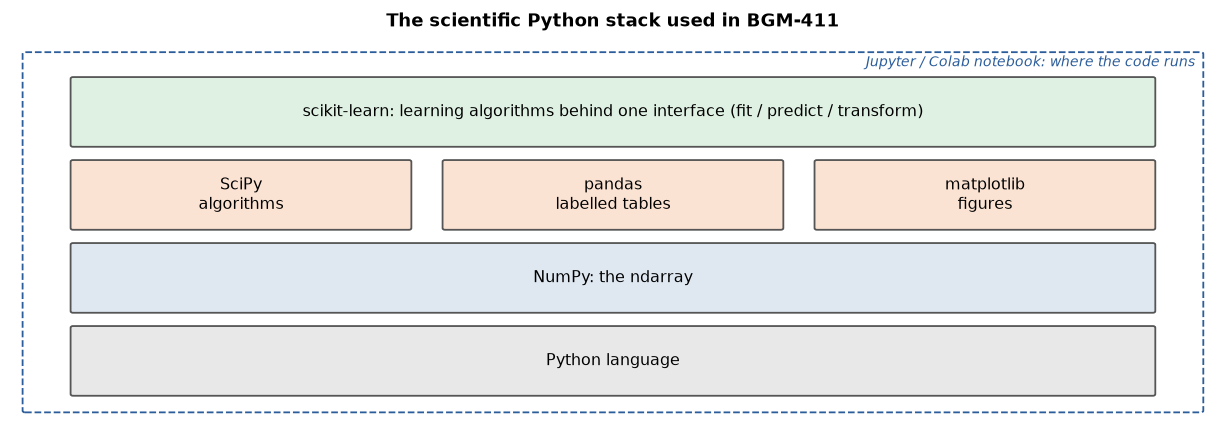

In [2]:
# The scientific Python stack as a dependency diagram: each layer uses the layers below it.
from matplotlib.patches import FancyBboxPatch
def draw_stack():
    layers = [  # (row, boxes on that row, colour)
        (0, [("Python language", 0.5, 9.0)], "#e8e8e8"),
        (1, [("NumPy: the ndarray", 0.5, 9.0)], "#dfe7f1"),
        (2, [("SciPy\nalgorithms", 0.5, 2.8), ("pandas\nlabelled tables", 3.6, 2.8), ("matplotlib\nfigures", 6.7, 2.8)], "#fbe3d3"),
        (3, [("scikit-learn: learning algorithms behind one interface (fit / predict / transform)", 0.5, 9.0)], "#dff1e2"),
    ]
    fig, ax = plt.subplots(figsize=(9.5, 3.4))
    for row, boxes, colour in layers:
        for label, x0, w in boxes:
            ax.add_patch(FancyBboxPatch((x0, row + 0.1), w, 0.8, boxstyle="round,pad=0.02", fc=colour, ec="#555"))
            ax.text(x0 + w / 2, row + 0.5, label, ha="center", va="center", fontsize=9)
    ax.add_patch(FancyBboxPatch((0.1, -0.1), 9.8, 4.3, boxstyle="round,pad=0.02", fill=False, ec="#2b5d9b", ls="--"))
    ax.text(9.85, 4.05, "Jupyter / Colab notebook: where the code runs", ha="right", fontsize=8, color="#2b5d9b", style="italic")
    ax.set_xlim(0, 10); ax.set_ylim(-0.2, 4.4); ax.axis("off")
    ax.set_title("The scientific Python stack used in BGM-411")
    fig.tight_layout()
draw_stack()

<p class="caption"><b>Figure 1.</b> The libraries of the course and their dependencies. Arrays flow upward: a CSV file becomes a pandas table, then a NumPy array, which enters a scikit-learn estimator; matplotlib draws the result.</p>

### 1.2 Notebooks, cells and the kernel

A <strong>Jupyter notebook</strong> interleaves text, code and the code's output,<sup class="c"><a href="#r9">[9]</a></sup><sup class="c"><a href="#r10">[10]</a></sup> and is the standard environment of data science because an analysis can be read as a narrative and re-executed as a program.<sup class="c"><a href="#r11">[11]</a></sup> Google Colab is a hosted Jupyter notebook with the stack pre-installed.

The document is divided into <strong>cells</strong>. A code cell is sent, with <kbd>Shift</kbd>+<kbd>Enter</kbd>, to a <strong>kernel</strong>: a Python process that runs while the notebook is open and keeps every variable, function and library in one shared memory, the <em>namespace</em>. A variable defined in one cell is available in every cell run afterwards, wherever those cells sit on the page. Run the next cell once, read the output, then run it again.

In [3]:
# Kernel state: a variable created in one cell survives, and is visible to every cell run later.
if "run_count" not in dir():         # true only the first time this cell is executed
    run_count = 0
run_count += 1
print("This cell has been executed", run_count, "time(s) since the kernel started.")

user_vars = sorted(k for k, v in globals().items()
                   if not k.startswith("_") and not callable(v) and type(v).__name__ != "module")
print("Variables currently alive in the kernel:", user_vars)

This cell has been executed 1 time(s) since the kernel started.
Variables currently alive in the kernel: ['run_count']


The first execution prints 1; the second prints 2, although the code has not changed. A cell's output depends on the <em>history</em> of what was run before it, which the execution count in brackets records: cells are numbered in the order run, not the order shown.

### 1.3 The danger of out-of-order execution

The next two cells set a threshold, count the tumours whose mean nuclear radius exceeds it, and then change the threshold.

In [4]:
# Cell A: load the breast-cancer data, set a threshold, and count the large tumours.
cancer = datasets.load_breast_cancer()            # the recurring dataset of the course (Section 3)
radius = cancer.data[:, 0]                        # column 0 is 'mean radius' (micrometres)
threshold = 15.0
n_large = int((radius > threshold).sum())
print(f"{n_large} of {radius.size} tumours have mean radius > {threshold} µm")

173 of 569 tumours have mean radius > 15.0 µm


The two outputs disagree about the threshold. Re-running only cell A would now print a count for 20 while its source still says <code>threshold = 15.0</code>, because cell B overwrote the variable; nothing on the page signals it, and a reader who runs the notebook from the top gets a different result. Of 1.4 million notebooks on GitHub, only about a quarter ran without error and about 4 % reproduced their displayed outputs, out-of-order execution being a main cause;<sup class="c"><a href="#r13">[13]</a></sup> a study of a million notebooks found the same pattern.<sup class="c"><a href="#r12">[12]</a></sup>

<div class="box warn"><h4>The rule that prevents it</h4><p>Before trusting any notebook, use <em>Runtime → Restart and run all</em> (Colab) or <em>Kernel → Restart &amp; Run All</em> (Jupyter). If the result changes, the notebook depended on hidden state. Every notebook of this course is built that way; write your reports to survive the same test.<sup class="c"><a href="#r14">[14]</a></sup></p></div>

<div class="exercise"><h4>Exercise 1</h4><p>Re-run cell A without re-running cell B and compare the count. Then delete <code>threshold = 20.0</code> from cell B and <em>Restart and run all</em>: a clean notebook defines every variable once, above every use.</p></div>

## 2. Python essentials you must have

Only the constructs that Units 1–9 use are covered; the tutorials listed at the end fill any gap.

### 2.1 Lists, tuples, dictionaries and slicing

A <strong>list</strong> is an ordered, changeable sequence in square brackets; a <strong>tuple</strong> an ordered, unchangeable sequence in parentheses (NumPy reports shapes as tuples); a <strong>dictionary</strong> maps keys to values in braces (scikit-learn returns parameters as dictionaries). <strong>Slicing</strong> with <code>start:stop:step</code> selects part of any sequence: positions count from 0, <code>stop</code> is <em>not</em> included, negative positions count from the end.

In [5]:
# Cell B: the threshold is changed... but n_large was computed with the OLD value and is not recomputed.
threshold = 20.0
print(f"threshold is now {threshold}, but n_large is still {n_large} (computed with threshold 15.0)")

threshold is now 20.0, but n_large is still 173 (computed with threshold 15.0)


<code>features[:3]</code> returns three names (positions 0, 1, 2) because position 3 is excluded — the same rule makes <code>X[:, 0:2]</code> select two columns later. You will write <code>X.shape[0]</code> for "the number of samples" dozens of times.

### 2.2 Comprehensions, functions and floating-point numbers

A <strong>list comprehension</strong> builds a list in one line: <code>[expression for item in sequence if condition]</code>. A <strong>function</strong> documents itself with a <em>docstring</em>, may have default arguments, and may return several values as a tuple. One fact about numbers: Python's <code>float</code> is a 64-bit binary number, most decimal fractions (0.1 among them) cannot be represented exactly, and arithmetic carries rounding errors of order $10^{-16}$.<sup class="c"><a href="#r15">[15]</a></sup> Never compare computed floats with <code>==</code>; use <code>np.isclose</code> or <code>np.allclose</code>.

In [6]:
# Lists, tuples, dictionaries and slicing, on the names of the 30 breast-cancer features.
features = [str(f) for f in cancer.feature_names]   # a list: ordered, mutable, square brackets
print(type(features).__name__, "of", len(features), "names")
print("features[:3]   ->", features[:3])             # positions 0, 1, 2 (stop is excluded)
print("features[-2:]  ->", features[-2:])            # the last two
print("features[::10] ->", features[::10])           # every tenth

shape = cancer.data.shape                           # a tuple: ordered, immutable, parentheses
print("shape", shape, "-> rows", shape[0], "columns", shape[1], "| type:", type(shape).__name__)

class_names = {0: "malignant", 1: "benign"}          # a dict: key -> value
print("first patient:", class_names[cancer.target[0]], "| missing key with default:", class_names.get(2, "unknown"))
units = {"mean radius": "µm", "mean texture": "grey-level s.d.", "mean area": "µm²"}
for name, unit in units.items():
    print(f"  {name:13s} is measured in {unit}")

list of 30 names
features[:3]   -> ['mean radius', 'mean texture', 'mean perimeter']
features[-2:]  -> ['worst symmetry', 'worst fractal dimension']
features[::10] -> ['mean radius', 'radius error', 'worst radius']
shape (569, 30) -> rows 569 columns 30 | type: tuple
first patient: malignant | missing key with default: unknown
  mean radius   is measured in µm
  mean texture  is measured in grey-level s.d.
  mean area     is measured in µm²


Ten of the thirty names start with "mean". The function returned two numbers in one tuple, unpacked into <code>m</code> and <code>s</code>. And <code>0.1 + 0.2</code> is not <code>0.3</code> in binary floating point — the discrepancy sits in the seventeenth digit — while <code>np.isclose</code> reports equality within tolerance.

<div class="exercise"><h4>Exercise 2</h4><p>Write a comprehension listing the features whose name contains "concave". Then make <code>summarise</code> return the minimum and maximum as well, and unpack all four values.</p></div>

## 3. NumPy: the array

### 3.1 The ndarray: shape, dtype and indexing

NumPy's <code>ndarray</code> is a block of memory holding numbers of one single type, plus a <strong>shape</strong> that says how to read the block as a grid.<sup class="c"><a href="#r4">[4]</a></sup><sup class="c"><a href="#r16">[16]</a></sup> Three attributes describe it: <code>shape</code> (a tuple of dimensions), <code>ndim</code> (1 for a vector, 2 for a matrix) and <code>dtype</code> (<code>float64</code> for measurements, <code>int64</code> for counts and labels, <code>bool</code> for masks). The uniform type is what makes NumPy fast.

The breast-cancer data of Street, Wolberg and Mangasarian — 569 fine-needle aspirates, each described by 30 features computed from an image of the cell nuclei and labelled benign or malignant by biopsy<sup class="c"><a href="#r17">[17]</a></sup><sup class="c"><a href="#r18">[18]</a></sup> — arrive as such an array. A matrix is indexed as <code>X[row, column]</code>, each part a position, a slice or (Section 3.2) a boolean mask; a bare colon means "all".

In [7]:
# Comprehensions, a documented function with a default argument, and why floats are compared with a tolerance.
mean_features = [f for f in features if f.startswith("mean")]          # list comprehension with a condition
print(len(mean_features), "features start with 'mean':", mean_features[:4], "...")
name_length = {f: len(f) for f in mean_features[:3]}                   # dict comprehension
print(name_length)

def summarise(values, label="values"):
    '''Return (mean, standard deviation) of a 1-D sequence of numbers.'''
    arr = np.asarray(values, dtype=float)
    print(f"summarising {arr.size} {label}")
    return arr.mean(), arr.std()                                        # two values -> a tuple

m, s = summarise(radius, label="radii")                                 # tuple unpacking
print(f"mean radius: mean {m:.2f} µm, s.d. {s:.2f} µm")

print("0.1 + 0.2 == 0.3 ?", 0.1 + 0.2 == 0.3, "| 0.1 + 0.2 =", 0.1 + 0.2, "| np.isclose:", np.isclose(0.1 + 0.2, 0.3))

10 features start with 'mean': ['mean radius', 'mean texture', 'mean perimeter', 'mean area'] ...
{'mean radius': 11, 'mean texture': 12, 'mean perimeter': 14}
summarising 569 radii
mean radius: mean 14.13 µm, s.d. 3.52 µm
0.1 + 0.2 == 0.3 ? False | 0.1 + 0.2 = 0.30000000000000004 | np.isclose: True


The matrix has 569 rows (patients) and 30 columns (features) of 64-bit floats, and the label vector 569 integers with values 0 and 1; scikit-learn codes malignant as 0 and benign as 1. A single column, <code>X[:, 3]</code>, has shape <code>(569,)</code> — one dimension, not <code>(569, 1)</code> — a distinction Section 6.2 returns to. <em>Mean area</em> spans thousands of units while other features span hundredths — the disparity behind Section 6.4.

### 3.2 Boolean masks

Comparing an array with a number gives an array of <code>bool</code> of the same shape, the <strong>mask</strong>. As an index it selects the elements where it is <code>True</code>; its <code>sum()</code> counts them; masks combine with <code>&amp;</code>, <code>|</code> and <code>~</code> — not with <code>and</code>, <code>or</code>, <code>not</code>, which do not work element-wise — and each comparison needs parentheses because <code>&amp;</code> binds more tightly than <code>&gt;</code>.

In [8]:
# The data matrix X and the label vector y as NumPy arrays: attributes and basic indexing.
X, y = cancer.data, cancer.target
print("X:", type(X).__name__, "shape", X.shape, "ndim", X.ndim, "dtype", X.dtype, "size", X.size)
print("y:", "shape", y.shape, "dtype", y.dtype, "distinct values", np.unique(y), "(0 = malignant, 1 = benign)")

print("X[0, :4]  (patient 0, first four features) ->", X[0, :4].round(2))
print("X[:3, 0]  (first three patients, feature 0) ->", X[:3, 0].round(2))
print("X[-1, -1] (last patient, last feature)      ->", X[-1, -1])
area = X[:, 3]                                  # column 3 is 'mean area': a 1-D view of the column
print("mean area ranges from", area.min(), "to", area.max(), "| shape of a column:", area.shape)

X: ndarray shape (569, 30) ndim 2 dtype float64 size 17070
y: shape (569,) dtype int64 distinct values [0 1] (0 = malignant, 1 = benign)
X[0, :4]  (patient 0, first four features) -> [  17.99   10.38  122.8  1001.  ]
X[:3, 0]  (first three patients, feature 0) -> [17.99 20.57 19.69]
X[-1, -1] (last patient, last feature)      -> 0.07039
mean area ranges from 143.5 to 2501.0 | shape of a column: (569,)


The 212 malignant and 357 benign cases differ by about five micrometres in mean nuclear radius, and two conditions together isolate a subgroup in which malignancy is far more frequent than in the whole sample (37 %).

### 3.3 Vectorisation: why loops are slow

A Python <code>for</code> loop over an array runs the interpreter's machinery once per element; a NumPy expression such as <code>(A - mu) ** 2</code> runs one compiled loop for the whole array. Writing array expressions instead of element loops is <strong>vectorisation</strong>, the most important performance habit in scientific Python.<sup class="c"><a href="#r4">[4]</a></sup> The cell computes the Euclidean distance from every row of a matrix to the column mean — the operation of the nearest-centroid classifier of Unit 1 — both ways and times them (best of three runs).

In [9]:
# Boolean masks: select the malignant cases, compare the classes, and combine two conditions.
malignant = (y == 0)                                        # a boolean array, one entry per patient
print("mask dtype:", malignant.dtype, "| malignant:", malignant.sum(), "| benign:", (~malignant).sum())
print("mean radius — malignant: %.2f µm, benign: %.2f µm" % (X[malignant, 0].mean(), X[~malignant, 0].mean()))

large_and_smooth = (X[:, 0] > 15) & (X[:, 4] > 0.10)        # radius > 15 µm AND smoothness > 0.10
print(large_and_smooth.sum(), "tumours are large and smooth;",
      f"{(y[large_and_smooth] == 0).mean():.1%} of them are malignant")

mask dtype: bool | malignant: 212 | benign: 357
mean radius — malignant: 17.46 µm, benign: 12.15 µm
87 tumours are large and smooth; 97.7% of them are malignant


<p class="caption"><b>Figure 2.</b> Time to compute the distance of every row to the column mean versus the number of rows, with a Python double loop (orange) and a vectorised expression (blue), on logarithmic axes. Both grow roughly linearly, but the vectorised version is faster by a factor of tens to hundreds (last column of the table). Exact times depend on the machine; the ratio much less so.</p>

The two functions return identical arrays (the <code>assert</code> checks it), so the difference is purely speed: one to two orders of magnitude. Whenever you write <code>for i in range(X.shape[0])</code>, an array expression almost always exists, built from the two ingredients below.

### 3.4 Broadcasting

In <code>A - mu</code>, <code>A</code> has shape <code>(n, 30)</code> and <code>mu</code> shape <code>(30,)</code>: NumPy subtracts the vector from <em>every row</em>. This is <strong>broadcasting</strong>: dimensions are compared from the right, two dimensions are compatible when equal or when one is 1 (or missing), and the smaller array is virtually repeated along it.<sup class="c"><a href="#r4">[4]</a></sup> Standardising a matrix (Section 6) is one broadcast expression.

### 3.5 Axis semantics: the most common error in the course

Every reduction (<code>sum</code>, <code>mean</code>, <code>std</code>, <code>argmax</code>…) takes an <code>axis</code> argument naming the dimension <em>to be collapsed</em>. For shape <code>(n_rows, n_cols)</code>, <code>X.mean(axis=0)</code> collapses the rows and leaves one value <em>per column</em>, shape <code>(n_cols,)</code>; <code>X.mean(axis=1)</code> collapses the columns and leaves one value <em>per row</em>. Students read "axis=0" as "operate on the rows"; the correct reading is "operate <em>along</em> the rows, down each column". Trace it on paper:

$$\mathbf{M} = \begin{pmatrix} 1 & 2 & 3 \\ 4 & 5 & 6 \end{pmatrix}, \qquad
\texttt{M.mean(axis=0)} = \left(\tfrac{1+4}{2},\ \tfrac{2+5}{2},\ \tfrac{3+6}{2}\right) = (2.5,\ 3.5,\ 4.5), \qquad
\texttt{M.mean(axis=1)} = \left(\tfrac{1+2+3}{3},\ \tfrac{4+5+6}{3}\right) = (2,\ 5).$$

Feature statistics — the mean of each feature over all patients — are always <code>axis=0</code> in this course.

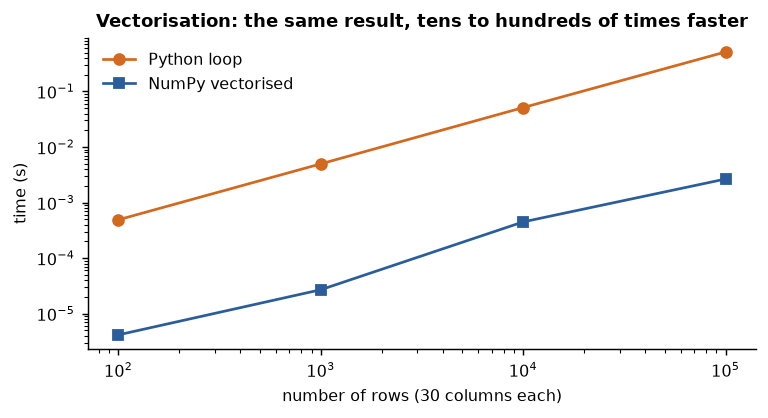

,rows (x 30 columns),loop (s),vectorised (s),speed-up
0,100,0.000491,0.000004,118
1,1000,0.004976,0.000027,184
2,10000,0.051282,0.000449,114
3,100000,0.513692,0.002655,193


In [10]:
# Loop versus vectorised computation of the distance of every row to the column mean, timed (best of 3).
def dist_loop(A, mu):
    '''Element-by-element Python loops: one interpreter step per number.'''
    out = np.empty(A.shape[0])
    for i in range(A.shape[0]):
        s = 0.0
        for j in range(A.shape[1]):
            s += (A[i, j] - mu[j]) ** 2
        out[i] = s ** 0.5
    return out

def dist_vec(A, mu):
    '''The same computation as one array expression: broadcasting, squaring, summing over columns.'''
    return np.sqrt(((A - mu) ** 2).sum(axis=1))

def best_time(fn, *args, repeats=3):
    '''Shortest wall-clock time of `repeats` calls, in seconds.'''
    return min((lambda t0: (fn(*args), time.perf_counter() - t0)[1])(time.perf_counter()) for _ in range(repeats))

rng = np.random.default_rng(0)
sizes, t_loop, t_vec = [100, 1_000, 10_000, 100_000], [], []
for n in sizes:
    A = rng.normal(size=(n, 30)); mu = A.mean(axis=0)
    assert np.allclose(dist_loop(A, mu), dist_vec(A, mu))          # identical results
    t_loop.append(best_time(dist_loop, A, mu)); t_vec.append(best_time(dist_vec, A, mu))
timing = pd.DataFrame({"rows (x 30 columns)": sizes, "loop (s)": t_loop, "vectorised (s)": t_vec})
timing["speed-up"] = (timing["loop (s)"] / timing["vectorised (s)"]).round(0).astype(int)

fig, ax = plt.subplots(figsize=(6, 3.3))
ax.loglog(sizes, t_loop, "o-", color="#d2691e", label="Python loop"); ax.loglog(sizes, t_vec, "s-", color="#2b5d9b", label="NumPy vectorised")
ax.set_xlabel("number of rows (30 columns each)"); ax.set_ylabel("time (s)"); ax.legend(frameon=False); ax.set_title("Vectorisation: the same result, tens to hundreds of times faster")
fig.tight_layout()
timing.round(6)

The hand trace is confirmed: axis 0 gives three column means, axis 1 two row means, no axis the grand mean 3.5. On the data, <code>Z</code> keeps the shape of <code>X</code> with column means zero and column standard deviations exactly 1. The wrong axis gives 569 numbers; subtracting them fails with the broadcasting error shown, and forcing it with a reshape "works" while quietly centring each <em>patient</em>, destroying the comparability of features.

In [11]:
# Axis semantics by hand and on the data; broadcasting; and what the wrong axis does.
M = np.array([[1, 2, 3], [4, 5, 6]])
print("M.mean(axis=0) =", M.mean(axis=0), "| M.mean(axis=1) =", M.mean(axis=1), "| M.mean() =", M.mean())

mu, sd = X.mean(axis=0), X.std(axis=0)                     # one value per FEATURE
print("X", X.shape, "-> mu", mu.shape, "sd", sd.shape)
Z = (X - mu) / sd                                          # broadcasting: (569, 30) - (30,) -> (569, 30)
print("Z", Z.shape, "| column means all ~0:", np.abs(Z.mean(axis=0)).max() < 1e-12, "| column s.d.:", Z.std(axis=0).round(6)[:3], "...")

wrong = X.mean(axis=1)                                     # one value per PATIENT: not a feature statistic
print("X.mean(axis=1) has shape", wrong.shape, "- one number per patient, not per feature")
try:
    X - wrong
except ValueError as e:
    print("X - wrong -> ValueError:", e)
print("(X - wrong[:, None]).shape =", (X - wrong[:, None]).shape, "<- runs, but centres each PATIENT, which is meaningless here")

M.mean(axis=0) = [2.5 3.5 4.5] | M.mean(axis=1) = [2. 5.] | M.mean() = 3.5
X (569, 30) -> mu (30,) sd (30,)
Z (569, 30) | column means all ~0: True | column s.d.: [1. 1. 1.] ...
X.mean(axis=1) has shape (569,) - one number per patient, not per feature
X - wrong -> ValueError: operands could not be broadcast together with shapes (569,30) (569,) 
(X - wrong[:, None]).shape = (569, 30) <- runs, but centres each PATIENT, which is meaningless here


<p class="caption"><b>Figure 3.</b> A 3 × 4 matrix with its reductions. Orange arrows run <em>along</em> axis 0 (down the rows) and produce one value per column; blue arrows run along axis 1 and produce one value per row. The parameter names the axis that disappears.</p>

### 3.6 Worked example by hand: standardisation changes a decision

Four training cases use two features with very different scales, <em>mean area</em> (hundreds of µm²) and <em>mean smoothness</em> (hundredths), with values chosen so that the arithmetic is exact.

| case | area $x_1$ | smoothness $x_2$ | class |
|---|---|---|---|
| 1 | 350 | 0.095 | benign |
| 2 | 750 | 0.065 | benign |
| 3 | 650 | 0.135 | malignant |
| 4 | 1050 | 0.105 | malignant |

**Centroids on raw features.** $\boldsymbol{\mu}_B = \left(\tfrac{350+750}{2}, \tfrac{0.095+0.065}{2}\right) = (550,\ 0.080)$, $\boldsymbol{\mu}_M = \left(\tfrac{650+1050}{2}, \tfrac{0.135+0.105}{2}\right) = (850,\ 0.120)$.

**Classify** $\mathbf{x} = (650,\ 0.135)$ by nearest centroid (Unit 1, Section 5): $d_B = \sqrt{(650-550)^2 + (0.135-0.080)^2} = \sqrt{10000 + 0.003} \approx 100.0$; $d_M = \sqrt{(650-850)^2 + (0.135-0.120)^2} = \sqrt{40000 + 0.0002} \approx 200.0$. The case is called <strong>benign</strong>. Smoothness contributed 0.003 to a sum of 10,000: ignored because its unit is small.

**Standardise.** Column means $\bar{x}_1 = \tfrac{350+750+650+1050}{4} = 700$, $\bar{x}_2 = \tfrac{0.095+0.065+0.135+0.105}{4} = 0.100$. Population standard deviations (the convention of <code>StandardScaler</code> and <code>np.std</code>): deviations of $x_1$ are $(-350, +50, -50, +350)$, so $s_1 = \sqrt{\tfrac{2(350^2+50^2)}{4}} = \sqrt{62500} = 250$; deviations of $x_2$ are $(-0.005, -0.035, +0.035, +0.005)$, so $s_2 = \sqrt{\tfrac{2(0.005^2+0.035^2)}{4}} = \sqrt{0.000625} = 0.025$. Each value becomes $z = (x - \bar{x})/s$:

| case | $z_1$ | $z_2$ | class |
|---|---|---|---|
| 1 | $(350-700)/250 = -1.4$ | $(0.095-0.100)/0.025 = -0.2$ | benign |
| 2 | $+0.2$ | $-1.4$ | benign |
| 3 | $-0.2$ | $+1.4$ | malignant |
| 4 | $+1.4$ | $+0.2$ | malignant |
| new | $(650-700)/250 = -0.2$ | $(0.135-0.100)/0.025 = +1.4$ | ? |

**Standardised centroids** $\boldsymbol{\mu}_B^z = (-0.6, -0.8)$, $\boldsymbol{\mu}_M^z = (0.6, 0.8)$; **distances** $d_B = \sqrt{0.4^2 + 2.2^2} = \sqrt{5} \approx 2.236$, $d_M = \sqrt{0.8^2 + 0.6^2} = 1.000$. The case is now <strong>malignant</strong>: same data, same classifier, opposite decision; only the units changed.

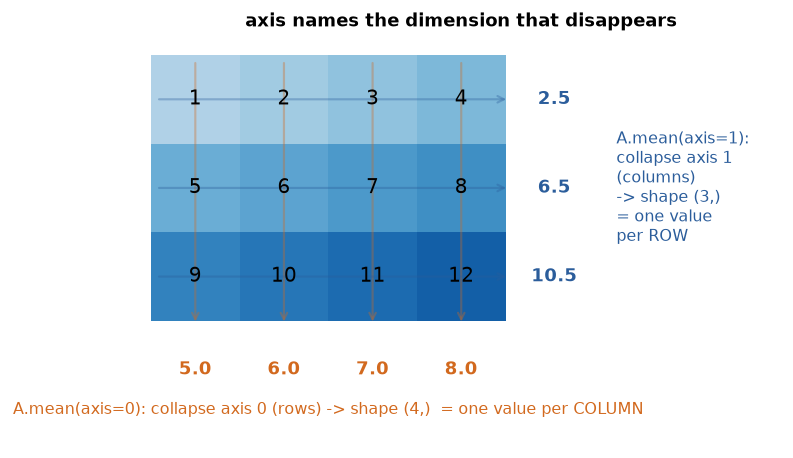

In [12]:
# Schematic of axis semantics on a 3 x 4 matrix: axis=0 collapses rows (one value per column), axis=1 collapses columns.
def draw_axes_schematic():
    A = np.arange(1, 13).reshape(3, 4)
    fig, ax = plt.subplots(figsize=(7.5, 3.6))
    ax.imshow(A, cmap="Blues", vmin=-6, vmax=16)
    for i in range(3):
        for j in range(4):
            ax.text(j, i, str(A[i, j]), ha="center", va="center", fontsize=11, zorder=5)
    for j in range(4):                                 # column means below the matrix (axis=0)
        ax.text(j, 3.05, f"{A[:, j].mean():.1f}", ha="center", va="center", fontsize=10, color="#d2691e", weight="bold")
        ax.annotate("", xy=(j, 2.55), xytext=(j, -0.45), arrowprops=dict(arrowstyle="->", color="#d2691e", lw=1.2, alpha=0.35))
    for i in range(3):                                 # row means to the right of the matrix (axis=1)
        ax.text(4.05, i, f"{A[i].mean():.1f}", ha="center", va="center", fontsize=10, color="#2b5d9b", weight="bold")
        ax.annotate("", xy=(3.55, i), xytext=(-0.45, i), arrowprops=dict(arrowstyle="->", color="#2b5d9b", lw=1.2, alpha=0.35))
    ax.text(1.5, 3.55, "A.mean(axis=0): collapse axis 0 (rows) -> shape (4,)  = one value per COLUMN", ha="center", fontsize=9, color="#d2691e")
    ax.text(4.75, 1, "A.mean(axis=1):\ncollapse axis 1\n(columns)\n-> shape (3,)\n= one value\nper ROW", ha="left", va="center", fontsize=9, color="#2b5d9b")
    ax.set_xlim(-0.6, 6.6); ax.set_ylim(3.9, -0.7); ax.axis("off")
    ax.set_title("axis names the dimension that disappears")
    fig.tight_layout()
draw_axes_schematic()

Every number matches the hand computation — means 700 and 0.100, standard deviations 250 and 0.025, distances 100 and 200 raw versus 2.236 and 1.000 standardised, and the reversal from B to M. Section 6.4 repeats the experiment on all 569 patients and 30 features.

<div class="box key"><h4>Key idea</h4><p>Any method that adds or compares features — distances, variances, gradients — is dominated by the feature with the largest numbers; standardisation ($z = (x-\bar{x})/s$) removes the units. Distance-based classifiers (Units 1 and 3), principal components (Unit 5) and neural networks (Unit 6) need it; decision trees and random forests (Unit 4) do not, because they consider one feature at a time.</p></div>

### 3.7 Random numbers

NumPy's legacy interface, <code>np.random.seed(0)</code> then <code>np.random.normal(...)</code>, uses one hidden global generator (the Mersenne Twister<sup class="c"><a href="#r19">[19]</a></sup>), on which scikit-learn's <code>random_state</code> arguments are built. The modern interface, <code>rng = np.random.default_rng(seed)</code>, creates an explicit generator object (PCG64<sup class="c"><a href="#r20">[20]</a></sup>) whose methods — <code>normal</code>, <code>integers</code>, <code>choice</code>, <code>permutation</code>, <code>random</code> — give the same sequence for the same seed.

In [13]:
# Confirmation of the hand trace: nearest centroid on raw and on standardised features.
T = np.array([[350, 0.095], [750, 0.065], [650, 0.135], [1050, 0.105]])     # 4 training cases x 2 features
lab = np.array(["B", "B", "M", "M"])
x_new = np.array([650, 0.135])

def nearest_centroid(train, labels, x):
    '''Return the distances of x to each class centroid and the predicted class.'''
    centroids = {c: train[labels == c].mean(axis=0) for c in ("B", "M")}
    d = {c: np.linalg.norm(x - m) for c, m in centroids.items()}
    return d, min(d, key=d.get)

mu, sd = T.mean(axis=0), T.std(axis=0)                                      # axis=0: per feature
print(f"column means: area {mu[0]:.0f}, smoothness {mu[1]:.3f} | column s.d.: area {sd[0]:.0f}, smoothness {sd[1]:.3f}")
d_raw, pred_raw = nearest_centroid(T, lab, x_new)
Tz, xz = (T - mu) / sd, (x_new - mu) / sd                                    # broadcasting again
print("standardised training cases:\n", Tz.round(2), "\nstandardised new case:", xz.round(2))
d_z, pred_z = nearest_centroid(Tz, lab, xz)
print(f"raw features:          d_B = {d_raw['B']:.3f}, d_M = {d_raw['M']:.3f}  ->  {pred_raw}")
print(f"standardised features: d_B = {d_z['B']:.3f}, d_M = {d_z['M']:.3f}  ->  {pred_z}")

column means: area 700, smoothness 0.100 | column s.d.: area 250, smoothness 0.025
standardised training cases:
 [[-1.4 -0.2]
 [ 0.2 -1.4]
 [-0.2  1.4]
 [ 1.4  0.2]] 
standardised new case: [-0.2  1.4]
raw features:          d_B = 100.000, d_M = 200.000  ->  B
standardised features: d_B = 2.236, d_M = 1.000  ->  M


Two generators with seed 0 give the same three numbers; seed 1 gives others. A random permutation of the patient indices is how a training/test split is made (Section 6.3).

<div class="box bridge"><h4>Bridge to the official plan</h4><p>Laboratory 1 of the official plan introduces R's vectors, matrices, lists and data frames. A NumPy array is R's matrix, a <code>DataFrame</code> is R's data frame, a <code>dict</code> plays the role of a named list, and the idea of a tidy table — one row per observation, one column per variable — is the same.<sup class="c"><a href="#r21">[21]</a></sup> Two differences trip R users: Python counts from 0, and a slice excludes its end.</p></div>

## 4. pandas: labelled tables

### 4.1 Series and DataFrame

A <strong><code>DataFrame</code></strong> is a two-dimensional table whose columns have names, whose rows have labels (the <strong>index</strong>), and whose columns may differ in type;<sup class="c"><a href="#r6">[6]</a></sup> one column is a <strong><code>Series</code></strong>. A numeric column is a NumPy array underneath, so Section 3 applies to it. scikit-learn's loaders return a <code>DataFrame</code> with <code>as_frame=True</code>.

In [14]:
# Random numbers with default_rng: the same seed gives the same sequence; a different seed gives a different one.
rng_a, rng_b, rng_c = np.random.default_rng(0), np.random.default_rng(0), np.random.default_rng(1)
print("seed 0:", rng_a.normal(size=3).round(3))
print("seed 0:", rng_b.normal(size=3).round(3), "<- identical")
print("seed 1:", rng_c.normal(size=3).round(3), "<- different")

rng = np.random.default_rng(0)
print("integers 0-9:", rng.integers(0, 10, size=6), "| choice:", rng.choice(["A", "B", "O"], size=4),
      "| uniform [0,1):", rng.random(2).round(3))
print("a random permutation of the 569 patients, first five positions:", rng.permutation(569)[:5])

seed 0: [ 0.126 -0.132  0.64 ]
seed 0: [ 0.126 -0.132  0.64 ] <- identical
seed 1: [0.346 0.822 0.33 ] <- different
integers 0-9: [8 6 5 2 3 0] | choice: ['A' 'A' 'A' 'O'] | uniform [0,1): [0.913 0.607]
a random permutation of the 569 patients, first five positions: [142 253  81 389  85]


The frame has 569 rows and 31 columns — thirty float columns and the integer target — with a default integer index. The bare expression <code>df.head()</code> is rendered as a table — the idiom for looking at data; a bare <code>df</code> on 569 rows is the idiom to avoid (Section 7).

### 4.2 Selecting: loc, iloc and the trap of the filtered index

<code>df.loc[row_label, column_name]</code> selects <em>by label</em>, and a label slice <em>includes</em> its end; <code>df.iloc[row_position, column_position]</code> selects <em>by position</em> and excludes the end, like NumPy. On a fresh frame the two coincide, which hides the difference until a filter breaks it: filtering keeps the <em>original</em> labels, so the first row of a filtered frame may be labelled 82 and <code>.loc[0]</code> fails.

In [15]:
# The breast-cancer data as a DataFrame: shape, column types, one column as a Series, and the first rows.
cancer_df = datasets.load_breast_cancer(as_frame=True)
df = cancer_df.frame.copy()                         # 30 feature columns + 'target'
print(type(df).__name__, df.shape, "| index:", df.index[:3].tolist(), "...", "| columns:", df.columns[:2].tolist(), "...")
print("column types:\n" + df.dtypes.value_counts().to_string())

s = df["mean radius"]                               # one column is a Series
print("\nSeries:", s.name, "| shape", s.shape, "| dtype", s.dtype, "| first value", s.iloc[0], "| underlying NumPy:", type(s.to_numpy()).__name__)
print("printing the whole table would take", len(df.to_string().splitlines()), "lines; head() shows", len(df.head()), "rows:")
df.head()

DataFrame (569, 31) | index: [0, 1, 2] ... | columns: ['mean radius', 'mean texture'] ...
column types:
float64    30
int64       1

Series: mean radius | shape (569,) | dtype float64 | first value 17.99 | underlying NumPy: ndarray
printing the whole table would take 570 lines; head() shows 5 rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,...,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,...,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,...,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,...,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,...,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,...,0.2050,0.4000,0.1625,0.2364,0.07678,0


The label slice <code>0:2</code> returned three rows and the position slice two. After the filter, five tumours remain with their original patient numbers as labels; <code>.iloc[0]</code> finds the first, <code>.loc[0]</code> raises <code>KeyError</code>, and <code>reset_index(drop=True)</code> renumbers the rows. Use <code>.loc</code> with names and masks, <code>.iloc</code> with positions, and <code>reset_index(drop=True)</code> after filtering.

### 4.3 Filtering, grouping and aggregating

A boolean mask filters a frame as it filters an array. <strong><code>groupby</code></strong> splits the frame by the values of one column, applies an aggregation to each group and recombines the results into a table indexed by group — "split–apply–combine".<sup class="c"><a href="#r6">[6]</a></sup> The cell adds a readable <code>diagnosis</code> column (a <em>categorical</em>, Section 4.5) and compares the classes on three features; <code>observed=True</code> restricts the groups to categories actually present, a choice recent pandas versions require to be explicit.

In [16]:
# loc (labels) versus iloc (positions), and what happens to labels after filtering.
print("df.loc[0, 'mean radius'] =", df.loc[0, "mean radius"], "| df.iloc[0, 0] =", df.iloc[0, 0], "<- same cell, two addressing systems")
print("label slice loc[0:2] has", df.loc[0:2, ["mean radius", "mean texture"]].shape[0], "rows (end included);",
      "position slice iloc[0:2] has", df.iloc[0:2, 0:2].shape[0], "rows (end excluded)")

big = df[df["mean radius"] > 25]                    # a boolean mask filters rows; labels are KEPT
print("rows with mean radius > 25:", len(big), "| their labels:", big.index.tolist()[:6])
print("big.iloc[0, 0] =", big.iloc[0, 0], "(first row by position)")
try:
    big.loc[0, "mean radius"]
except KeyError as e:
    print("big.loc[0, 'mean radius'] -> KeyError:", e, "<- label 0 is not in the filtered frame")
big.reset_index(drop=True).loc[0, "mean radius"]    # reset_index renumbers 0..n-1; now label 0 exists

df.loc[0, 'mean radius'] = 17.99 | df.iloc[0, 0] = 17.99 <- same cell, two addressing systems
label slice loc[0:2] has 3 rows (end included); position slice iloc[0:2] has 2 rows (end excluded)
rows with mean radius > 25: 5 | their labels: [82, 180, 212, 352, 461]
big.iloc[0, 0] = 25.22 (first row by position)
big.loc[0, 'mean radius'] -> KeyError: 0 <- label 0 is not in the filtered frame


np.float64(25.22)

The grouped table has one row per class and a two-level column header (feature, statistic). Malignant tumours have a larger mean radius and roughly twice the mean area of benign ones, while mean smoothness differs by less than one standard deviation — the pattern the hand example of Section 3.6 was built on.

<div class="exercise"><h4>Exercise 3</h4><p>Replace the three features by the ten "worst" features and add <code>"median"</code> to the aggregation: which feature separates the classes by the most standard deviations? Then load <code>datasets.load_diabetes(as_frame=True)</code> — 442 patients, ten baseline variables and a measure of disease progression one year later<sup class="c"><a href="#r32">[32]</a></sup> — and group its target by <code>sex</code>.</p></div>

### 4.4 Missing values

Real clinical tables have gaps. pandas marks a missing value as <code>NaN</code> ("not a number", a special float): <code>isna()</code> detects it, <code>dropna()</code> removes rows containing it, <code>fillna(value)</code> replaces it, and <code>mean()</code> skips it by default — correct only if the gaps are unrelated to the quantity. scikit-learn estimators refuse arrays with <code>NaN</code>; gaps must be removed or <em>imputed</em> before <code>fit</code>. The cell punches 5 % holes at random into three columns.

In [17]:
# A readable class column, its counts, and a grouped summary of three features by diagnosis.
df["diagnosis"] = pd.Categorical(cancer_df.target_names[df["target"]], categories=["malignant", "benign"])
print(df["diagnosis"].value_counts().to_string())

summary = (df.groupby("diagnosis", observed=True)[["mean radius", "mean area", "mean smoothness"]]
             .agg(["mean", "std"]).round(3))
summary

diagnosis
benign       357
malignant    212


mean radius        mean area          mean smoothness       
                 mean    std      mean      std            mean    std
diagnosis                                                             
malignant      17.463  3.204   978.376  367.938           0.103  0.013
benign         12.147  1.781   462.790  134.287           0.092  0.013

About 5 % of each column is missing and about 16 % of rows have at least one gap — <code>dropna()</code> would discard them all, losing complete information in two of three columns. The means over available values are close to the complete-data means, as expected for random gaps; gaps that depend on the patient's condition would bias them. Median imputation fills every gap and keeps all rows; Supplement S1 explains why the median must be computed on the training data only, since an imputation statistic that has seen the test set is <em>leakage</em>.

### 4.5 dtypes and categorical variables

Every column has a <strong>dtype</strong>: <code>float64</code> or <code>int64</code> for numbers, a string type for text (<code>str</code> in pandas 3, <code>object</code> in older versions), and <strong><code>Categorical</code></strong> for labels from a small fixed set, which stores the categories once and an integer code per row. Categoricals use less memory, record that the values are nominal (or ordinal, with <code>ordered=True</code>), and expose the codes algorithms need.

In [18]:
# Missing values: detect, count, drop, and impute (median) in a copy of three columns with 5 % random gaps.
rng = np.random.default_rng(0)
cols = ["mean radius", "mean texture", "mean area"]
dfm = df[cols].mask(rng.random(df[cols].shape) < 0.05)       # True where the random number < 0.05 -> NaN
print("missing values per column:\n" + dfm.isna().sum().to_string())
print("complete rows:", len(dfm.dropna()), "of", len(dfm))
print("column means ignore NaN by default:", dfm.mean().round(2).tolist(), "| complete data:", df[cols].mean().round(2).tolist())

filled = dfm.fillna(dfm.median())                              # median imputation, column by column
print("missing after median imputation:", int(filled.isna().sum().sum()))
dfm.head()

missing values per column:
mean radius     32
mean texture    27
mean area       34
complete rows: 479 of 569
column means ignore NaN by default: [14.16, 19.29, 652.93] | complete data: [14.13, 19.29, 654.89]
missing after median imputation: 0


,mean radius,mean texture,mean area
0,17.99,10.38,NaN
1,NaN,17.77,1326.0
2,19.69,21.25,1203.0
3,11.42,20.38,NaN
4,20.29,NaN,1297.0


The same 569 labels occupy about ten times more memory as text than as a categorical. The codes follow the categories list (malignant = 0, benign = 1), and an <em>ordered</em> categorical such as tumour stage supports <code>min</code>, <code>max</code> and comparisons that an unordered one refuses.

### 4.6 Reading and writing files; from DataFrame to NumPy and back

Laboratory data arrive as CSV. <code>df.to_csv(path, index=False)</code> writes one; <code>pd.read_csv(path)</code> reads one and <em>infers</em> each column's type from its content — so a categorical comes back as text, and one stray character in a numeric column turns the whole column into text. <code>df.to_numpy()</code> drops the labels and returns the array; <code>pd.DataFrame(array, columns=names)</code> restores them. scikit-learn also accepts a <code>DataFrame</code> directly.

In [19]:
# dtypes: text versus categorical storage, categories and codes, and an ordered categorical.
as_text = df["diagnosis"].astype(str)
print("dtype as text:", as_text.dtype, "| as categorical:", df["diagnosis"].dtype)
print("memory (bytes): text", as_text.memory_usage(deep=True), "| categorical", df["diagnosis"].memory_usage(deep=True))
print("categories:", df["diagnosis"].cat.categories.tolist(), "| codes of the first five rows:", df["diagnosis"].cat.codes[:5].tolist())

stage = pd.Categorical(["II", "I", "IV", "II", "III"], categories=["I", "II", "III", "IV"], ordered=True)
print("ordered categorical:", list(stage), "| min", stage.min(), "| max", stage.max(), "| > II:", (stage > "II").tolist())

dtype as text: str | as categorical: category
memory (bytes): text 8734 | categorical 840
categories: ['malignant', 'benign'] | codes of the first five rows: [0, 0, 0, 0, 0]
ordered categorical: ['II', 'I', 'IV', 'II', 'III'] | min I | max IV | > II: [False, False, True, False, True]


The file is a little over a hundred kilobytes; it reads back with the same shape and identical values, and the categorical has become text, as predicted. Conversion to NumPy and back is lossless for numeric columns. The UCI repository distributes these data as a CSV,<sup class="c"><a href="#r18">[18]</a></sup> and this is how a dataset of your own enters the course's pipeline.

## 5. matplotlib: figures

### 5.1 The fig, ax interface

The implicit interface, <code>plt.plot(...)</code>, draws on "the current figure". The explicit one — <code>fig, ax = plt.subplots()</code> — returns a <strong>Figure</strong> (the page) and one or more <strong>Axes</strong> (plotting areas), and every drawing command is a method of an axes: <code>ax.scatter</code>, <code>ax.plot</code>, <code>ax.hist</code>, <code>ax.bar</code>, <code>ax.imshow</code>.<sup class="c"><a href="#r7">[7]</a></sup> The course uses the explicit interface only: with several panels there is no ambiguity about which receives a command. A legible figure has axis labels with units, a title, a legend when more than one series is drawn, and few colours.<sup class="c"><a href="#r22">[22]</a></sup>

In [20]:
# CSV round trip (written to a temporary folder and deleted afterwards), and DataFrame <-> NumPy conversion.
path = os.path.join(tempfile.gettempdir(), "breast_cancer_demo.csv")
df.to_csv(path, index=False)
print("written:", os.path.basename(path), "-", os.path.getsize(path) // 1024, "kB")
df_back = pd.read_csv(path)
print("read back:", df_back.shape, "| 'diagnosis' dtype after reading:", df_back["diagnosis"].dtype, "(categorical was lost)")
num = df.columns[:30]                                            # the 30 feature columns
print("numeric values identical after the round trip:", np.allclose(df[num], df_back[num]))

A = df[num].to_numpy()                                           # DataFrame -> ndarray (labels dropped)
print("to_numpy():", type(A).__name__, A.shape, A.dtype)
df_again = pd.DataFrame(A, columns=num)                          # ndarray -> DataFrame (labels restored)
print("back to DataFrame, equal to the original 30 columns:", df_again.equals(df[num]))
os.remove(path)

written: breast_cancer_demo.csv - 123 kB
read back: (569, 32) | 'diagnosis' dtype after reading: str (categorical was lost)
numeric values identical after the round trip: True
to_numpy(): ndarray (569, 30) float64
back to DataFrame, equal to the original 30 columns: True


<p class="caption"><b>Figure 4.</b> The four plot types the course uses, each class in its own colour: (a) scatter, two features per patient; (b) histogram of one feature per class; (c) empirical cumulative distribution — the same information as (b) without the bin width, the curves about five micrometres apart; (d) bar chart of the class counts, 357 and 212.</p>

Read the code as a pattern: <code>plt.subplots(2, 2)</code> returns axes indexed <code>axes[row, col]</code>; the loop over <code>groupby</code> draws each class with a consistent colour and label; <code>ax.set(...)</code> sets several properties at once; <code>fig.tight_layout()</code> removes overlaps.

### 5.2 Images, colour bars and saving

A matrix is drawn with <code>ax.imshow(matrix)</code>, which maps values to colours through a <em>colour map</em>; <code>fig.colorbar</code> adds the scale, and a signed quantity such as a correlation needs a diverging map centred on zero (<code>RdBu_r</code>, <code>vmin=-1, vmax=1</code>). <code>fig.savefig(path, dpi=..., bbox_inches="tight")</code> saves the figure in the format of the extension (<code>.png</code> for slides and web pages; <code>.pdf</code> or <code>.svg</code> for documents, because they scale without loss).

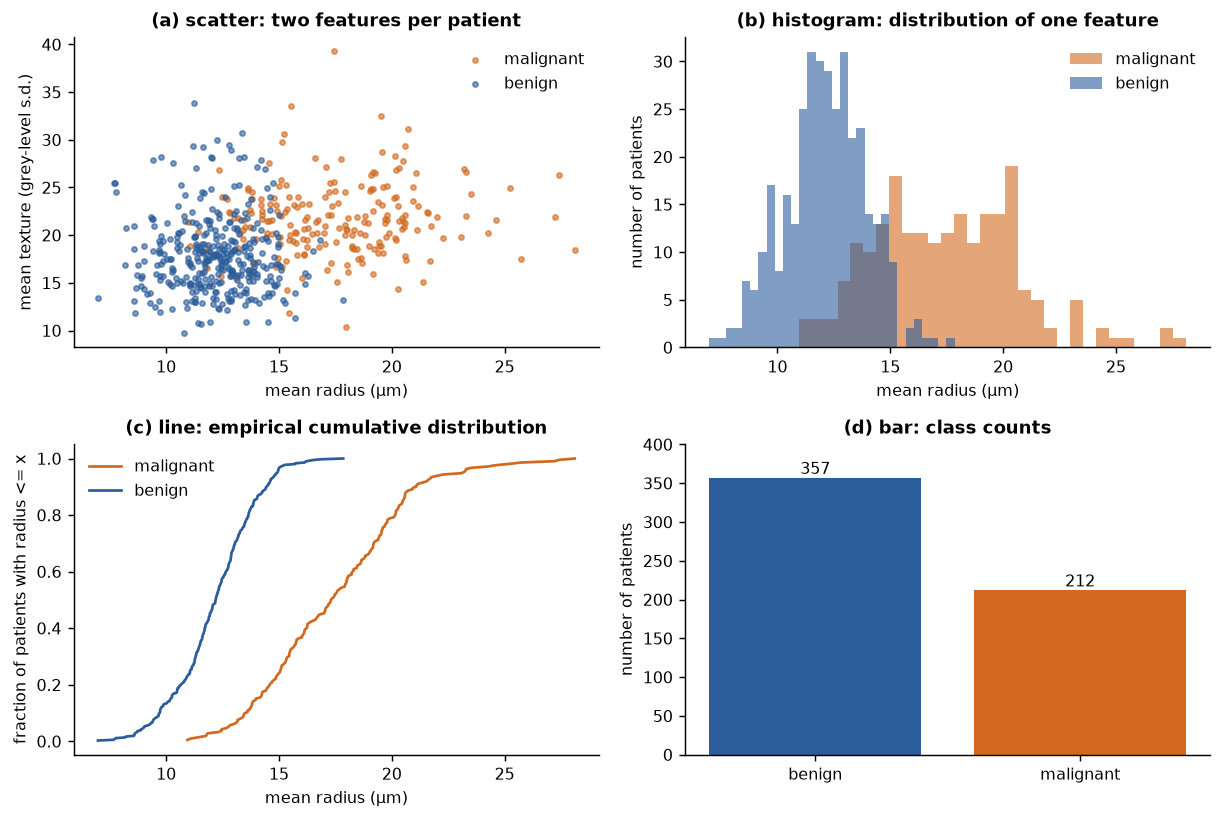

In [21]:
# Four plot types on one figure: scatter, histogram, line (empirical cumulative distribution) and bar.
colour = {"malignant": "#d2691e", "benign": "#2b5d9b"}
fig, axes = plt.subplots(2, 2, figsize=(9.5, 6.4))               # axes is a 2 x 2 array of Axes
for name, g in df.groupby("diagnosis", observed=True):          # one group per class
    axes[0, 0].scatter(g["mean radius"], g["mean texture"], s=8, alpha=0.6, color=colour[name], label=name)
    axes[0, 1].hist(g["mean radius"], bins=30, alpha=0.6, color=colour[name], label=name)
    r = np.sort(g["mean radius"].to_numpy())
    axes[1, 0].plot(r, np.arange(1, r.size + 1) / r.size, color=colour[name], label=name)
counts = df["diagnosis"].value_counts()
axes[1, 1].bar(counts.index.astype(str), counts.to_numpy(), color=[colour[c] for c in counts.index])
for v, c in zip(counts.to_numpy(), range(len(counts))):
    axes[1, 1].text(c, v + 5, str(v), ha="center", fontsize=9)

axes[0, 0].set(xlabel="mean radius (µm)", ylabel="mean texture (grey-level s.d.)", title="(a) scatter: two features per patient")
axes[0, 1].set(xlabel="mean radius (µm)", ylabel="number of patients", title="(b) histogram: distribution of one feature")
axes[1, 0].set(xlabel="mean radius (µm)", ylabel="fraction of patients with radius <= x", title="(c) line: empirical cumulative distribution")
axes[1, 1].set(ylabel="number of patients", title="(d) bar: class counts", ylim=(0, 400))
for ax in axes.ravel()[:3]:
    ax.legend(frameon=False)
fig.tight_layout()

<p class="caption"><b>Figure 5.</b> Pearson correlation between the ten mean features. Radius, perimeter and area are almost perfectly correlated (0.99–1.00) because they measure the same size; compactness, concavity and concave points form a second block; fractal dimension correlates weakly or negatively with size. Correlated features carry redundant information, which Unit 5 (dimensionality reduction) exploits.</p>

The printed line confirms that a PNG of well under a megabyte was written at 200 dpi. They are also why Section 3.6 paired <em>area</em> with <em>smoothness</em> rather than <em>radius</em>.

<div class="exercise"><h4>Exercise 4</h4><p>Change the colour map to <code>"viridis"</code> and remove <code>vmin</code> and <code>vmax</code>. Why is a sequential map a poor choice for a quantity symmetric about zero?</p></div>

## 6. The scikit-learn API

### 6.1 Estimators and the fit/predict/transform/score contract

Every scikit-learn algorithm is an <strong>estimator</strong> with the same small interface.<sup class="c"><a href="#r8">[8]</a></sup><sup class="c"><a href="#r23">[23]</a></sup>

- <strong>Construction</strong> sets <em>hyperparameters</em> — settings chosen by the analyst — and computes nothing: <code>KNeighborsClassifier(n_neighbors=5)</code>.
- <strong><code>fit(X, y)</code></strong> learns from data and stores the result in attributes whose names <em>end in an underscore</em> (<code>scaler.mean_</code>, <code>knn.classes_</code>); they exist only after <code>fit</code>.
- <strong><code>predict(X)</code></strong> (classifiers, regressors) returns one output per row; <strong><code>transform(X)</code></strong> (scalers, encoders, dimensionality reducers) returns a modified matrix; <code>fit_transform</code> does both.
- <strong><code>score(X, y)</code></strong> returns a default measure — accuracy for classifiers, $R^2$ for regressors.

The cell exercises the contract on <code>StandardScaler</code>, which performs the standardisation of Section 3.6, and checks it against NumPy.

saved figure_correlation.png - 166 kB at 200 dpi


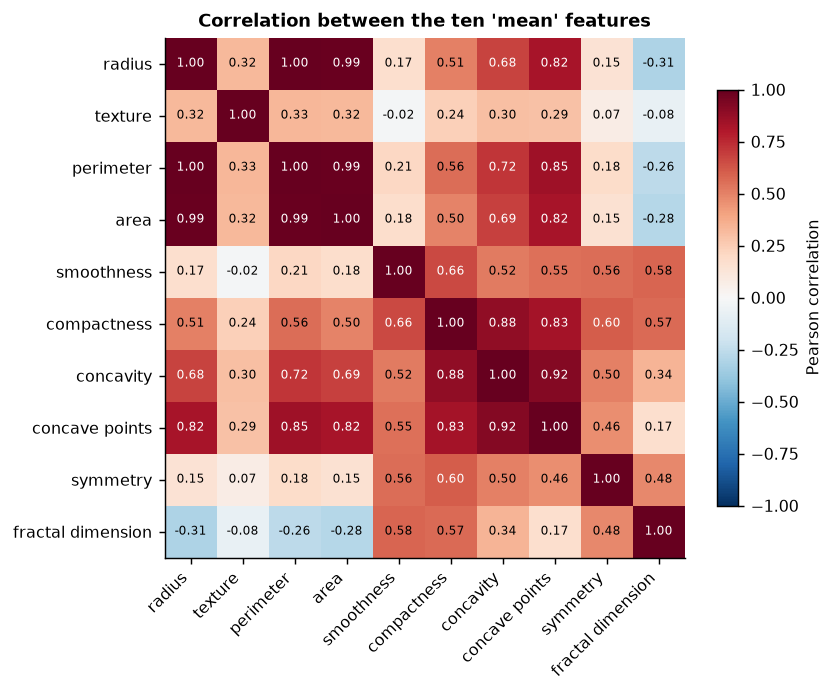

In [22]:
# imshow of a correlation matrix with a diverging colour map and annotations; saving the figure to a file.
mean_cols = [c for c in df.columns if c.startswith("mean")]
C = df[mean_cols].corr().to_numpy()                             # 10 x 10 Pearson correlations
short = [c.replace("mean ", "") for c in mean_cols]

fig, ax = plt.subplots(figsize=(6.6, 5.4))
im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(10), short, rotation=45, ha="right"); ax.set_yticks(range(10), short)
for i in range(10):
    for j in range(10):
        ax.text(j, i, f"{C[i, j]:.2f}", ha="center", va="center", fontsize=6.5, color="w" if abs(C[i, j]) > 0.6 else "k")
fig.colorbar(im, ax=ax, label="Pearson correlation", shrink=0.8)
ax.set_title("Correlation between the ten 'mean' features")
fig.tight_layout()

out = os.path.join(tempfile.gettempdir(), "figure_correlation.png")
fig.savefig(out, dpi=200, bbox_inches="tight")
print("saved", os.path.basename(out), "-", os.path.getsize(out) // 1024, "kB at 200 dpi"); os.remove(out)

Before <code>fit</code> the scaler has no <code>mean_</code>; after it, <code>mean_</code> and <code>scale_</code> hold one value per feature (the <code>axis=0</code> statistics of Section 3.5), and <code>transform</code> reproduces the broadcast NumPy expression to machine precision.

### 6.2 The (n_samples, n_features) contract

Every estimator expects <code>X</code> as a two-dimensional array of shape <code>(n_samples, n_features)</code> and <code>y</code> as a one-dimensional array of length <code>n_samples</code>. The most frequent violation is passing a single feature as shape <code>(569,)</code> instead of a column <code>(569, 1)</code>; the cell triggers the error on purpose.

In [23]:
# The estimator contract on StandardScaler: construct -> fit (learned attributes end in '_') -> transform.
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()                                  # construction: no computation yet
print("learned attribute 'mean_' exists before fit?", hasattr(scaler, "mean_"))
scaler.fit(X)                                              # learns one mean and one scale per feature
print("after fit: mean_[:3] =", scaler.mean_[:3].round(3), "| scale_[:3] =", scaler.scale_[:3].round(3), "| shapes", scaler.mean_.shape, scaler.scale_.shape)
Z_sk = scaler.transform(X)                                 # applies (x - mean_) / scale_
print("transform output:", type(Z_sk).__name__, Z_sk.shape)
print("identical to the NumPy expression (X - X.mean(axis=0)) / X.std(axis=0):", np.allclose(Z_sk, (X - X.mean(axis=0)) / X.std(axis=0)))
print("fit_transform in one call gives the same:", np.allclose(StandardScaler().fit_transform(X), Z_sk))

learned attribute 'mean_' exists before fit? False
after fit: mean_[:3] = [14.127 19.29  91.969] | scale_[:3] = [ 3.521  4.297 24.278] | shapes (30,) (30,)
transform output: ndarray (569, 30)
identical to the NumPy expression (X - X.mean(axis=0)) / X.std(axis=0): True
fit_transform in one call gives the same: True


The message says what is wrong and how to fix it — <code>reshape(-1, 1)</code> for a single feature, <code>reshape(1, -1)</code> for a single sample. After the reshape the classifier reports its two centroids, the class means of mean radius found in Section 3.2, and a training accuracy close to 0.9 — optimistic, because it is measured on the cases the centroids were computed from.

### 6.3 train_test_split

A model must be evaluated on cases it did not see during <code>fit</code>, or its performance is overstated (Supplement S1). <code>train_test_split</code> shuffles the rows and divides them into a training and a test set. Three arguments matter: <code>test_size</code> (the fraction held out, typically 0.2–0.3), <code>random_state</code> (the same split every time) and <code>stratify=y</code> (both sets keep the class proportions of the whole).

In [24]:
# A single feature must be a column (n_samples, 1), not a vector (n_samples,): the error and the fix.
from sklearn.neighbors import NearestCentroid
one_feature = X[:, 0]                                      # 'mean radius' as a 1-D array
print("shape passed:", one_feature.shape)
try:
    NearestCentroid().fit(one_feature, y)
except ValueError as e:
    print("ValueError:", str(e).splitlines()[0])
column = one_feature.reshape(-1, 1)                        # -1 means 'as many rows as needed'
print("after reshape(-1, 1):", column.shape)
nc_one = NearestCentroid().fit(column, y)
print("centroids (malignant, benign):", nc_one.centroids_.ravel().round(2), "| training accuracy with one feature:", round(nc_one.score(column, y), 3))

shape passed: (569,)
ValueError: Expected 2D array, got 1D array instead:
after reshape(-1, 1): (569, 1)
centroids (malignant, benign): [17.46 12.15] | training accuracy with one feature: 0.88


The 569 cases become 398 for training and 171 for testing, with the same fraction of benign cases in both to within one case. Every classifier below is fitted on <code>X_tr, y_tr</code> and scored on <code>X_te, y_te</code>.

### 6.4 Pipeline and StandardScaler: why scaling matters, on the full data

The scaler's statistics must be <em>learned on the training set</em> and <em>applied</em> to both sets; computing them on all the data lets the test cases influence the model — <strong>leakage</strong>, among the most common errors in published machine-learning research.<sup class="c"><a href="#r24">[24]</a></sup> A <strong><code>Pipeline</code></strong> enforces the order automatically: <code>make_pipeline(StandardScaler(), NearestCentroid())</code> is itself an estimator whose <code>fit</code> fits the scaler on the training data, transforms them and fits the classifier, and whose <code>predict</code> transforms new data with the <em>training</em> statistics. Whenever a model needs preprocessing in this course, the two are one pipeline object.

In [25]:
# A stratified 70/30 split, fixed by random_state so that every later cell sees the same cases.
from sklearn.model_selection import train_test_split
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
print("train:", X_tr.shape, y_tr.shape, "| test:", X_te.shape, y_te.shape)
print("fraction benign — all data: %.3f | train: %.3f | test: %.3f" % (y.mean(), y_tr.mean(), y_te.mean()))

train: (398, 30) (398,) | test: (171, 30) (171,)
fraction benign — all data: 0.627 | train: 0.628 | test: 0.626


<p class="caption"><b>Figure 6.</b> Standard deviation of each of the 30 features in the training set, before (orange) and after (blue) standardisation, on a logarithmic scale. Raw spreads range from about $10^{-3}$ (fractal-dimension and smoothness features) to several hundred (<em>mean area</em>, <em>worst area</em>): the Euclidean distance between two patients on raw features is, to a good approximation, the difference in their areas alone.</p>

The accuracy printed above the figure rises from about 0.88 to about 0.91 when the features are standardised — a quarter of the errors disappear without changing classifier or data, only units — because on raw features the two <em>area</em> columns dominate every distance.

<div class="box warn"><h4>Common error</h4><p>Fitting the scaler on the whole dataset before splitting (<code>StandardScaler().fit_transform(X)</code>, then <code>train_test_split</code>) is the classic leakage error. With 569 cases the effect is small; with cross-validation over many folds, or preprocessing that uses the labels, it can inflate reported performance substantially.<sup class="c"><a href="#r24">[24]</a></sup> Split first, then fit the pipeline on the training set.</p></div>

### 6.5 Hyperparameters: get_params and set_params; where to find documentation

Every estimator reports its hyperparameters with <code>get_params()</code> and changes them with <code>set_params(name=value)</code>; inside a pipeline the names are qualified with the step name and a double underscore, <code>kneighborsclassifier__n_neighbors</code>. The cell previews Unit 3 by varying the number of neighbours of a <em>k</em>-NN classifier, then shows an estimator's constructor signature and docstring. The full documentation is at scikit-learn.org; in Colab, <code>KNeighborsClassifier?</code> shows the same text.

test accuracy on 171 held-out cases — raw features: 0.877 | standardised (Pipeline): 0.912
pipeline steps: ['standardscaler', 'nearestcentroid']


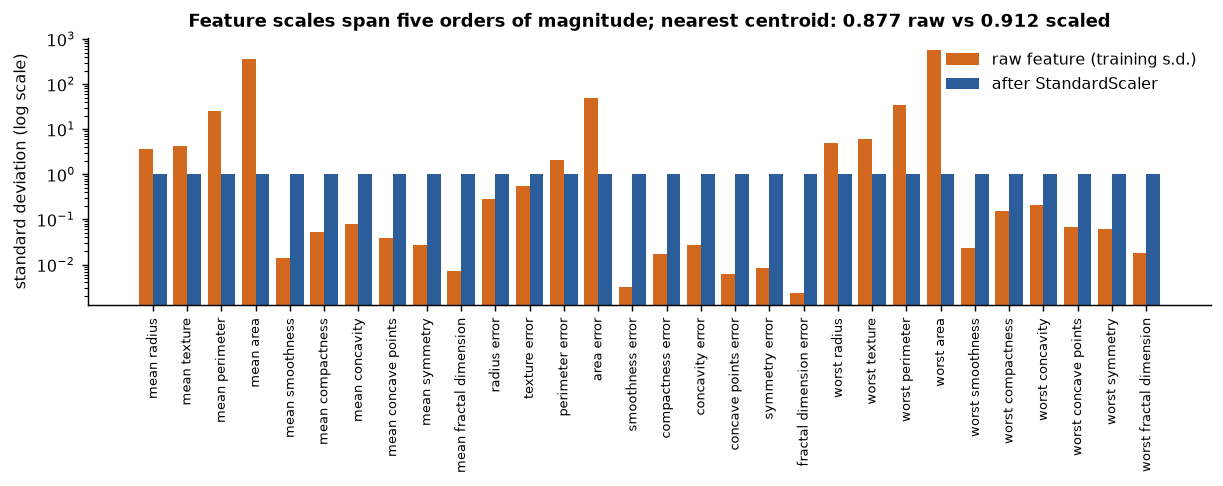

In [26]:
# Nearest centroid on all 30 raw features versus inside a Pipeline with StandardScaler; the feature scales explain the gap.
from sklearn.pipeline import make_pipeline
nc_raw = NearestCentroid().fit(X_tr, y_tr)
nc_scaled = make_pipeline(StandardScaler(), NearestCentroid()).fit(X_tr, y_tr)
acc_raw, acc_scaled = nc_raw.score(X_te, y_te), nc_scaled.score(X_te, y_te)
print(f"test accuracy on 171 held-out cases — raw features: {acc_raw:.3f} | standardised (Pipeline): {acc_scaled:.3f}")
print("pipeline steps:", [name for name, _ in nc_scaled.steps])

sd_raw = X_tr.std(axis=0)                                          # per-feature spread before scaling
sd_scaled = nc_scaled[0].transform(X_tr).std(axis=0)               # ... and after the scaler step
fig, ax = plt.subplots(figsize=(9.5, 3.8))
pos = np.arange(30)
ax.bar(pos - 0.2, sd_raw, 0.4, color="#d2691e", label="raw feature (training s.d.)")
ax.bar(pos + 0.2, sd_scaled, 0.4, color="#2b5d9b", label="after StandardScaler")
ax.set_yscale("log"); ax.set_xticks(pos, cancer.feature_names, rotation=90, fontsize=7)
ax.set_ylabel("standard deviation (log scale)"); ax.legend(frameon=False, loc="upper right")
ax.set_title(f"Feature scales span five orders of magnitude; nearest centroid: {acc_raw:.3f} raw vs {acc_scaled:.3f} scaled")
fig.tight_layout()

Every parameter of the pipeline is addressable by name, the default number of neighbours is 5, and the test accuracy varies only slightly with <em>k</em> on these data — all four values lie in a narrow band around 0.94–0.95; Unit 3 explains the trade-off behind the choice.

<div class="exercise"><h4>Exercise 5</h4><p>Remove the <code>StandardScaler</code> from the <em>k</em>-NN pipeline and repeat the loop (<code>get_params()</code> gives the new parameter name). How much accuracy is lost without scaling?</p></div>

## 7. Reproducibility and good habits

Reproducibility — another person re-running an analysis and obtaining the same result — is the minimum standard of computational science, and most published analyses fail it.<sup class="c"><a href="#r28">[28]</a></sup><sup class="c"><a href="#r29">[29]</a></sup> The guidelines of Sandve and colleagues<sup class="c"><a href="#r25">[25]</a></sup> and of Wilson and colleagues<sup class="c"><a href="#r26">[26]</a></sup><sup class="c"><a href="#r27">[27]</a></sup> reduce, for this course, to six habits.

1. **Fix every source of randomness:** <code>random_state=0</code> in every scikit-learn function that accepts it, <code>default_rng(0)</code> for NumPy.
2. **Record versions.** The first cell of every notebook prints them.
3. **Run from a clean kernel before trusting or submitting** (Section 1.3).
4. **Do not print whole tables.** <code>head()</code>, <code>describe().round(2)</code>, <code>shape</code> and <code>dtypes</code> tell you what you need.
5. **Name things for the reader:** <code>X_tr, X_te, y_tr, y_te</code>; <code>scaler</code>, <code>knn</code>, <code>tree</code>; <code>acc_raw</code>, <code>acc_scaled</code>; never <code>df2</code>, <code>temp</code>, <code>a</code>.
6. **Keep data findable:** load from a stable source (scikit-learn's loaders here; a repository with a DOI for your own data<sup class="c"><a href="#r30">[30]</a></sup>), never from a file on your desktop.

Notebooks make these habits easier — narrative, code and outputs are one re-runnable document<sup class="c"><a href="#r31">[31]</a></sup> — and also easier to break, through hidden state. The cell demonstrates habit 1.

In [27]:
# Hyperparameters of a pipeline: get_params, set_params with the step__parameter naming, and where the documentation lives.
from sklearn.neighbors import KNeighborsClassifier
import inspect
knn = make_pipeline(StandardScaler(), KNeighborsClassifier())
print("some parameter names:", [k for k in knn.get_params() if "__" in k][:5], "...")
print("default n_neighbors:", knn.get_params()["kneighborsclassifier__n_neighbors"])
for k in (1, 5, 15, 45):
    knn.set_params(kneighborsclassifier__n_neighbors=k).fit(X_tr, y_tr)
    print(f"  k = {k:2d}: test accuracy {knn.score(X_te, y_te):.3f}")

print("\nconstructor signature:", inspect.signature(KNeighborsClassifier))
print("first line of the docstring:", KNeighborsClassifier.__doc__.strip().splitlines()[0])

some parameter names: ['standardscaler__copy', 'standardscaler__with_mean', 'standardscaler__with_std', 'kneighborsclassifier__algorithm', 'kneighborsclassifier__leaf_size'] ...
default n_neighbors: 5
  k =  1: test accuracy 0.947
  k =  5: test accuracy 0.947
  k = 15: test accuracy 0.942
  k = 45: test accuracy 0.942

constructor signature: (n_neighbors=5, *, weights='uniform', algorithm='auto', leaf_size=30, p=2, metric='minkowski', metric_params=None, n_jobs=None)
first line of the docstring: Classifier implementing the k-nearest neighbors vote.


The two seeded calls return the same training indices; the two unseeded calls return different permutations, and would return others at the next execution, so no accuracy computed from them could be quoted in a report. Every number in this notebook is reproducible for this reason; the few that depend on the machine (the timings of Figure 2) are quoted as orders of magnitude.

## 8. A complete mini-project in twelve lines

Everything above assembles into the pipeline that Units 2–4 develop: load, split, standardise, fit, evaluate on held-out cases. The classifier is logistic regression, the subject of Unit 2; treat it for now as a black box that outputs a probability of each class. Read the cell as a whole — it is the skeleton of every supervised-learning experiment in the course.

In [28]:
# random_state: the same seed reproduces the same split; without a seed, two calls give two different splits.
idx = np.arange(10)                                             # ten 'patients' to split
seeded_1 = train_test_split(idx, test_size=0.3, random_state=0)[0]
seeded_2 = train_test_split(idx, test_size=0.3, random_state=0)[0]
unseeded_1 = train_test_split(idx, test_size=0.3)[0]
unseeded_2 = train_test_split(idx, test_size=0.3)[0]
print("random_state=0, first call :", seeded_1)
print("random_state=0, second call:", seeded_2, "<- identical:", np.array_equal(seeded_1, seeded_2))
print("no random_state, first call :", unseeded_1)
print("no random_state, second call:", unseeded_2, "<- different:", not np.array_equal(unseeded_1, unseeded_2))

random_state=0, first call : [9 1 6 7 3 0 5]
random_state=0, second call: [9 1 6 7 3 0 5] <- identical: True
no random_state, first call : [9 1 6 7 3 0 5]
no random_state, second call: [2 9 8 0 6 7 4] <- different: True


The model classifies about 96 % of the 171 held-out cases correctly. The <strong>confusion matrix</strong> breaks this down: the diagonal holds correct decisions, the off-diagonal cells the two kinds of error, which do not cost the same — a malignant tumour predicted benign (top right) is a missed cancer, a benign one predicted malignant (bottom left) an unnecessary biopsy.

In [29]:
# The whole workflow of a supervised-learning experiment: load -> split -> scale -> fit -> predict -> evaluate.
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
data = datasets.load_breast_cancer()                                                                   # 1. load
X_tr, X_te, y_tr, y_te = train_test_split(data.data, data.target, test_size=0.3, random_state=0, stratify=data.target)   # 2. split
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=0))             # 3. scale + classifier
model.fit(X_tr, y_tr)                                                                                  # 4. fit on training cases only
y_pred = model.predict(X_te)                                                                           # 5. predict the held-out cases
print(f"test accuracy: {accuracy_score(y_te, y_pred):.3f} on {len(y_te)} held-out cases")              # 6. evaluate
cm = confusion_matrix(y_te, y_pred)                                                                    # rows: true class, columns: predicted
print(pd.DataFrame(cm, index=["true malignant", "true benign"], columns=["predicted malignant", "predicted benign"]))

test accuracy: 0.959 on 171 held-out cases
                predicted malignant  predicted benign
true malignant                   61                 3
true benign                       4               103


<p class="caption"><b>Figure 7.</b> (a) The confusion matrix of the twelve-line model on the 171 test cases. (b) The predicted probability of the benign class for each test case, coloured by true class: most malignant cases receive a probability near 0 and most benign cases near 1; the errors are the cases that cross the dashed threshold at 0.5. Moving the threshold trades one kind of error for the other (Supplement S1).</p>

<div class="box bridge"><h4>Where this leads</h4><p>Unit 1 reuses <code>load_breast_cancer</code>, boolean masks, nearest centroid and <code>train_test_split</code> exactly as here. Unit 2 opens the logistic-regression box; Unit 3 puts Bayesian classifiers, support vector machines and <em>k</em>-NN inside the same <code>Pipeline</code>; Supplement S1 replaces the single split with cross-validation.</p></div>

## 9. Summary

You should now be able to explain, without notes:

- What a kernel is, why a cell's output depends on execution order, and why "Restart and run all" is the test of a trustworthy notebook.
- Slicing with the stop excluded; floats compared with <code>np.isclose</code>; <code>shape</code>, <code>dtype</code>, boolean masks, vectorisation and broadcasting.
- That <code>axis</code> names the dimension that disappears: <code>axis=0</code> gives one value per column, <code>axis=1</code> one per row.
- The standardisation formula $z = (x - \bar{x})/s$, by hand, and why it can reverse a nearest-centroid decision.
- <code>loc</code> versus <code>iloc</code> and the filtered-index trap; <code>groupby(...).agg(...)</code>; <code>isna</code>/<code>dropna</code>/<code>fillna</code>; categoricals; the CSV round trip and <code>to_numpy()</code>.
- The estimator contract, the <code>(n_samples, n_features)</code> rule, <code>train_test_split</code>, <code>Pipeline</code>, <code>get_params</code>/<code>set_params</code>; why the scaler is fitted on the training set only; the six habits of Section 7.

## 10. Self-assessment

<details><summary>1. A colleague's notebook shows execution counts [3], [1], [7], [2] from top to bottom and a final accuracy of 0.98. What should you do before believing the number, and why?</summary>Restart the kernel and run all cells in order. Non-consecutive counts show out-of-order execution, so the displayed outputs may not follow from the code on the page (Section 1.3).</details>

<details><summary>2. What does <code>features[2:5]</code> return for a list of 30 names, and how many elements does it have?</summary>Positions 2, 3 and 4 — three elements; the stop position 5 is excluded (Section 2.1).</details>

<details><summary>3. Without running code: for <code>M = np.array([[2, 4], [6, 8], [10, 12]])</code>, give <code>M.shape</code>, <code>M.mean(axis=0)</code> and <code>M.mean(axis=1)</code>.</summary><code>(3, 2)</code>; axis 0 collapses the rows: $(6, 8)$; axis 1 collapses the columns: $(3, 7, 11)$ (Section 3.5).</details>

<details><summary>4. <code>(X[:, 0] > 15) and (X[:, 4] > 0.1)</code> raises an error. Why, and what is the correct form?</summary><code>and</code> tries to reduce each array to one truth value, which is ambiguous for 569 booleans. Use <code>&amp;</code> with parentheses: <code>(X[:, 0] &gt; 15) &amp; (X[:, 4] &gt; 0.1)</code> (Section 3.2).</details>

<details><summary>5. In the example of Section 3.6 (area: mean 700, s.d. 250; smoothness: mean 0.100, s.d. 0.025), standardise an area of 950 and a smoothness of 0.075 by hand.</summary>$z_1 = (950 - 700)/250 = 1.0$; $z_2 = (0.075 - 0.100)/0.025 = -1.0$: both one standard deviation from the mean, in opposite directions.</details>

<details><summary>6. Why does nearest centroid improve when the 30 features are standardised, while a decision tree would not?</summary>Nearest centroid adds squared differences across features; on raw features the <em>area</em> columns dominate the sum and the other 28 features are effectively ignored. A tree thresholds one feature at a time, so rescaling leaves its splits unchanged (Sections 3.6 and 6.4).</details>

<details><summary>7. After <code>sub = df[df["mean area"] > 1000]</code>, <code>sub.loc[0, "mean area"]</code> raises <code>KeyError</code> but <code>sub.iloc[0]["mean area"]</code> works. Explain, and name the method that makes <code>.loc[0]</code> valid.</summary>Filtering keeps the original labels and patient 0 is not in <code>sub</code>; <code>iloc[0]</code> addresses the first row by position; <code>sub.reset_index(drop=True)</code> renumbers the rows (Section 4.2).</details>

<details><summary>8. What does <code>df.groupby("diagnosis", observed=True)["mean texture"].agg(["median", "count"])</code> compute?</summary>Per diagnosis class, the median of mean texture and the number of patients: a 2 × 2 table indexed by diagnosis (Section 4.3).</details>

<details><summary>9. A CSV is read with <code>pd.read_csv</code> and the column <code>glucose</code> has dtype <code>str</code> although it should be numeric. Most likely cause, and how to locate it?</summary>At least one entry is not parseable as a number ("n/a", a comma decimal separator, a unit), which forces the whole column to text. <code>pd.to_numeric(df["glucose"], errors="coerce")</code> turns the offenders into <code>NaN</code>, which locates them (Section 4.6).</details>

<details><summary>10. What is wrong with <code>Z = StandardScaler().fit_transform(X)</code>; <code>Z_tr, Z_te, y_tr, y_te = train_test_split(Z, y, random_state=0)</code>; <code>model.fit(Z_tr, y_tr)</code>?</summary>The scaler's statistics were computed on all 569 cases, including the future test set: leakage. Split first, then fit a <code>Pipeline(StandardScaler, model)</code> on the training set only (Section 6.4).</details>

<details><summary>11. An estimator has attributes <code>n_neighbors</code> and <code>classes_</code>. Which is a hyperparameter and which was learned, and how do you know?</summary><code>classes_</code> was learned by <code>fit</code>: learned attributes carry a trailing underscore and do not exist before <code>fit</code>; <code>n_neighbors</code> is set at construction and reported by <code>get_params()</code> (Sections 6.1 and 6.5).</details>

<details><summary>12. Two students run the twelve-line mini-project and obtain 0.959 and 0.941. Give two possible causes, in the order you would check them.</summary>A missing or different <code>random_state</code> in <code>train_test_split</code> (different held-out cases); then different library versions (compare the setup cell). (Sections 1.3 and 7).</details>

## Glossary

<dl class="gloss">
<dt>axis</dt><dd>In a NumPy reduction, the dimension that is collapsed: <code>axis=0</code> yields one value per column, <code>axis=1</code> one per row.</dd>
<dt>Boolean mask</dt><dd>An array of <code>True</code>/<code>False</code> produced by a comparison and used as an index to select elements or rows.</dd>
<dt>Broadcasting</dt><dd>NumPy's rule for combining arrays of different shapes: dimensions are compared from the right and a dimension of size 1 (or missing) is virtually repeated.</dd>
<dt>Categorical</dt><dd>A pandas dtype storing labels as a fixed list of categories plus one integer code per row; may be ordered.</dd>
<dt>Kernel</dt><dd>The background Python process that executes code cells and keeps all variables between them.</dd>
<dt>Estimator</dt><dd>Any scikit-learn object with a <code>fit</code> method; predictors add <code>predict</code> and <code>score</code>, transformers add <code>transform</code>.</dd>
<dt>Hyperparameter</dt><dd>A setting chosen before fitting; distinct from learned quantities, whose names end in an underscore.</dd>
<dt>Leakage</dt><dd>Any flow of information from the test data into the training of a model, including preprocessing statistics computed before splitting; inflates reported performance.</dd>
<dt>loc / iloc</dt><dd>pandas selection by label (slice end included) / by integer position (slice end excluded).</dd>
<dt>ndarray</dt><dd>NumPy's <em>n</em>-dimensional array: a block of elements of one dtype with a shape.</dd>
<dt>Pipeline</dt><dd>A scikit-learn estimator chaining transformers and a final estimator, fitting each step on the training data in order and applying the same steps to new data.</dd>
<dt>random_state / seed</dt><dd>The integer that initialises a pseudo-random generator; the same seed reproduces the same sequence, split or simulation.</dd>
<dt>Standardisation (z-score)</dt><dd>Transforming each feature by $z = (x - \bar{x})/s$ to mean 0 and standard deviation 1; implemented by <code>StandardScaler</code>.</dd>
<dt>Vectorisation</dt><dd>Computing with whole arrays, in compiled code, instead of element-by-element loops.</dd>
</dl>

## References and further reading

<ol class="refs">
<li id="r1">Oliphant TE. Python for scientific computing. <em>Comput Sci Eng</em>. 2007;9(3):10–20. <a href="https://doi.org/10.1109/MCSE.2007.58">doi:10.1109/MCSE.2007.58</a></li>
<li id="r2">Pérez F, Granger BE, Hunter JD. Python: an ecosystem for scientific computing. <em>Comput Sci Eng</em>. 2011;13(2):13–21. <a href="https://doi.org/10.1109/MCSE.2010.119">doi:10.1109/MCSE.2010.119</a></li>
<li id="r3">Millman KJ, Aivazis M. Python for scientists and engineers. <em>Comput Sci Eng</em>. 2011;13(2):9–12. <a href="https://doi.org/10.1109/MCSE.2011.36">doi:10.1109/MCSE.2011.36</a></li>
<li id="r4">Harris CR, Millman KJ, van der Walt SJ, et al. Array programming with NumPy. <em>Nature</em>. 2020;585:357–362. <a href="https://doi.org/10.1038/s41586-020-2649-2">doi:10.1038/s41586-020-2649-2</a></li>
<li id="r5">Virtanen P, Gommers R, Oliphant TE, et al. SciPy 1.0: fundamental algorithms for scientific computing in Python. <em>Nat Methods</em>. 2020;17:261–272. <a href="https://doi.org/10.1038/s41592-019-0686-2">doi:10.1038/s41592-019-0686-2</a></li>
<li id="r6">McKinney W. Data structures for statistical computing in Python. In: van der Walt S, Millman J, eds. <em>Proceedings of the 9th Python in Science Conference (SciPy 2010)</em>. 2010:56–61. <a href="https://doi.org/10.25080/Majora-92bf1922-00a">doi:10.25080/Majora-92bf1922-00a</a></li>
<li id="r7">Hunter JD. Matplotlib: a 2D graphics environment. <em>Comput Sci Eng</em>. 2007;9(3):90–95. <a href="https://doi.org/10.1109/MCSE.2007.55">doi:10.1109/MCSE.2007.55</a></li>
<li id="r8">Pedregosa F, Varoquaux G, Gramfort A, et al. Scikit-learn: machine learning in Python. <em>J Mach Learn Res</em>. 2011;12:2825–2830. <a href="https://jmlr.org/papers/v12/pedregosa11a.html">jmlr.org/papers/v12/pedregosa11a.html</a> (the journal does not assign DOIs; publisher page given)</li>
<li id="r9">Pérez F, Granger BE. IPython: a system for interactive scientific computing. <em>Comput Sci Eng</em>. 2007;9(3):21–29. <a href="https://doi.org/10.1109/MCSE.2007.53">doi:10.1109/MCSE.2007.53</a></li>
<li id="r10">Kluyver T, Ragan-Kelley B, Pérez F, et al. Jupyter Notebooks — a publishing format for reproducible computational workflows. In: Loizides F, Schmidt B, eds. <em>Positioning and Power in Academic Publishing: Players, Agents and Agendas</em>. IOS Press; 2016:87–90. <a href="https://doi.org/10.3233/978-1-61499-649-1-87">doi:10.3233/978-1-61499-649-1-87</a></li>
<li id="r11">Perkel JM. Why Jupyter is data scientists' computational notebook of choice. <em>Nature</em>. 2018;563:145–146. <a href="https://doi.org/10.1038/d41586-018-07196-1">doi:10.1038/d41586-018-07196-1</a></li>
<li id="r12">Rule A, Tabard A, Hollan JD. Exploration and explanation in computational notebooks. In: <em>Proceedings of the 2018 CHI Conference on Human Factors in Computing Systems</em>. ACM; 2018: paper 32. <a href="https://doi.org/10.1145/3173574.3173606">doi:10.1145/3173574.3173606</a></li>
<li id="r13">Pimentel JF, Murta L, Braganholo V, Freire J. A large-scale study about quality and reproducibility of Jupyter notebooks. In: <em>2019 IEEE/ACM 16th International Conference on Mining Software Repositories (MSR)</em>. 2019:507–517. <a href="https://doi.org/10.1109/MSR.2019.00077">doi:10.1109/MSR.2019.00077</a></li>
<li id="r14">Rule A, Birmingham A, Zuniga C, et al. Ten simple rules for writing and sharing computational analyses in Jupyter Notebooks. <em>PLoS Comput Biol</em>. 2019;15(7):e1007007. <a href="https://doi.org/10.1371/journal.pcbi.1007007">doi:10.1371/journal.pcbi.1007007</a></li>
<li id="r15">Goldberg D. What every computer scientist should know about floating-point arithmetic. <em>ACM Comput Surv</em>. 1991;23(1):5–48. <a href="https://doi.org/10.1145/103162.103163">doi:10.1145/103162.103163</a></li>
<li id="r16">van der Walt S, Colbert SC, Varoquaux G. The NumPy array: a structure for efficient numerical computation. <em>Comput Sci Eng</em>. 2011;13(2):22–30. <a href="https://doi.org/10.1109/MCSE.2011.37">doi:10.1109/MCSE.2011.37</a></li>
<li id="r17">Street WN, Wolberg WH, Mangasarian OL. Nuclear feature extraction for breast tumor diagnosis. <em>Proc SPIE</em>. 1993;1905:861–870. <a href="https://doi.org/10.1117/12.148698">doi:10.1117/12.148698</a></li>
<li id="r18">Wolberg WH, Mangasarian OL, Street N, Street WN. Breast Cancer Wisconsin (Diagnostic) [dataset]. UCI Machine Learning Repository; 1993. <a href="https://doi.org/10.24432/C5DW2B">doi:10.24432/C5DW2B</a></li>
<li id="r19">Matsumoto M, Nishimura T. Mersenne Twister: a 623-dimensionally equidistributed uniform pseudo-random number generator. <em>ACM Trans Model Comput Simul</em>. 1998;8(1):3–30. <a href="https://doi.org/10.1145/272991.272995">doi:10.1145/272991.272995</a></li>
<li id="r20">O'Neill ME. PCG: a family of simple fast space-efficient statistically good algorithms for random number generation. Technical Report HMC-CS-2014-0905. Harvey Mudd College; 2014. <a href="https://www.pcg-random.org/paper.html">pcg-random.org/paper.html</a> (technical report without DOI; author's page given)</li>
<li id="r21">Wickham H. Tidy data. <em>J Stat Softw</em>. 2014;59(10):1–23. <a href="https://doi.org/10.18637/jss.v059.i10">doi:10.18637/jss.v059.i10</a></li>
<li id="r22">Rougier NP, Droettboom M, Bourne PE. Ten simple rules for better figures. <em>PLoS Comput Biol</em>. 2014;10(9):e1003833. <a href="https://doi.org/10.1371/journal.pcbi.1003833">doi:10.1371/journal.pcbi.1003833</a></li>
<li id="r23">Buitinck L, Louppe G, Blondel M, et al. API design for machine learning software: experiences from the scikit-learn project. <em>ECML PKDD Workshop: Languages for Data Mining and Machine Learning</em>. 2013. arXiv:1309.0238. <a href="https://doi.org/10.48550/arXiv.1309.0238">doi:10.48550/arXiv.1309.0238</a></li>
<li id="r24">Kapoor S, Narayanan A. Leakage and the reproducibility crisis in machine-learning-based science. <em>Patterns</em>. 2023;4(9):100804. <a href="https://doi.org/10.1016/j.patter.2023.100804">doi:10.1016/j.patter.2023.100804</a></li>
<li id="r25">Sandve GK, Nekrutenko A, Taylor J, Hovig E. Ten simple rules for reproducible computational research. <em>PLoS Comput Biol</em>. 2013;9(10):e1003285. <a href="https://doi.org/10.1371/journal.pcbi.1003285">doi:10.1371/journal.pcbi.1003285</a></li>
<li id="r26">Wilson G, Aruliah DA, Brown CT, et al. Best practices for scientific computing. <em>PLoS Biol</em>. 2014;12(1):e1001745. <a href="https://doi.org/10.1371/journal.pbio.1001745">doi:10.1371/journal.pbio.1001745</a></li>
<li id="r27">Wilson G, Bryan J, Cranston K, Kitzes J, Nederbragt L, Teal TK. Good enough practices in scientific computing. <em>PLoS Comput Biol</em>. 2017;13(6):e1005510. <a href="https://doi.org/10.1371/journal.pcbi.1005510">doi:10.1371/journal.pcbi.1005510</a></li>
<li id="r28">Baker M. 1,500 scientists lift the lid on reproducibility. <em>Nature</em>. 2016;533:452–454. <a href="https://doi.org/10.1038/533452a">doi:10.1038/533452a</a></li>
<li id="r29">Stodden V, McNutt M, Bailey DH, et al. Enhancing reproducibility for computational methods. <em>Science</em>. 2016;354(6317):1240–1241. <a href="https://doi.org/10.1126/science.aah6168">doi:10.1126/science.aah6168</a></li>
<li id="r30">Wilkinson MD, Dumontier M, Aalbersberg IJ, et al. The FAIR Guiding Principles for scientific data management and stewardship. <em>Sci Data</em>. 2016;3:160018. <a href="https://doi.org/10.1038/sdata.2016.18">doi:10.1038/sdata.2016.18</a></li>
<li id="r31">Beg M, Taka J, Kluyver T, et al. Using Jupyter for reproducible scientific workflows. <em>Comput Sci Eng</em>. 2021;23(2):36–46. <a href="https://doi.org/10.1109/MCSE.2021.3052101">doi:10.1109/MCSE.2021.3052101</a></li>
<li id="r32">Efron B, Hastie T, Johnstone I, Tibshirani R. Least angle regression. <em>Ann Stat</em>. 2004;32(2):407–499. <a href="https://doi.org/10.1214/009053604000000067">doi:10.1214/009053604000000067</a> (source of the diabetes dataset)</li>
</ol>

<h4>Textbooks</h4>
<ul>
<li>McKinney W. <em>Python for Data Analysis</em>. 3rd ed. O'Reilly; 2022. — By the author of pandas; the NumPy and pandas chapters cover Sections 3 and 4 in depth. Free online at wesmckinney.com/book.</li>
<li>VanderPlas J. <em>Python Data Science Handbook</em>. 2nd ed. O'Reilly; 2023. — NumPy, pandas, matplotlib and scikit-learn in one volume; free online at jakevdp.github.io/PythonDataScienceHandbook.</li>
<li>Géron A. <em>Hands-On Machine Learning with Scikit-Learn, Keras and TensorFlow</em>. 3rd ed. O'Reilly; 2022. — Chapter 2 is an end-to-end project that extends Section 8.</li>
<li>James G, Witten D, Hastie T, Tibshirani R, Taylor J. <em>An Introduction to Statistical Learning with Applications in Python</em>. Springer; 2023. — The Python laboratories at the end of each chapter; free PDF at statlearning.com.</li>
<li>Downey AB. <em>Think Python</em>. 3rd ed. O'Reilly; 2024. — For the Python language itself (Section 2), if you need more than a review; free online at greenteapress.com.</li>
</ul>

<h4>Online resources</h4>
<ul>
<li>The official Python tutorial — <a href="https://docs.python.org/3/tutorial/">docs.python.org/3/tutorial</a>; chapters 3–5 cover Section 2.</li>
<li>NumPy: the absolute basics for beginners — <a href="https://numpy.org/doc/stable/user/absolute_beginners.html">numpy.org/doc/stable/user/absolute_beginners.html</a>; and the broadcasting guide in the same user guide.</li>
<li>pandas: 10 minutes to pandas — <a href="https://pandas.pydata.org/docs/user_guide/10min.html">pandas.pydata.org/docs/user_guide/10min.html</a>; and "Indexing and selecting data" for <code>loc</code>/<code>iloc</code>.</li>
<li>matplotlib quick start guide — <a href="https://matplotlib.org/stable/users/explain/quick_start.html">matplotlib.org/stable/users/explain/quick_start.html</a>; and the gallery for examples of every plot type.</li>
<li>scikit-learn: getting started and the user guide — <a href="https://scikit-learn.org/stable/getting_started.html">scikit-learn.org/stable/getting_started.html</a>; the API reference has one page per estimator; the "Common pitfalls" page covers leakage and <code>random_state</code>.</li>
<li>Google Colab — <a href="https://colab.research.google.com">colab.research.google.com</a>; "Welcome to Colab" explains cells, runtimes and how to save a copy of a notebook to your Drive.</li>
</ul>

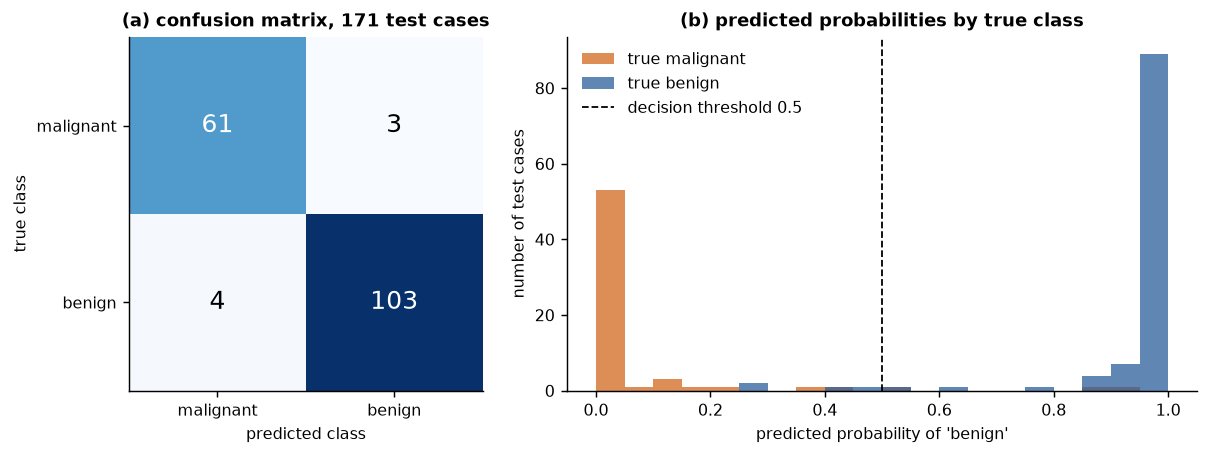

In [30]:
# The confusion matrix as an image, and the predicted probability of 'benign' for the held-out cases by true class.
proba_benign = model.predict_proba(X_te)[:, 1]                     # column 1 = probability of class 1 (benign)
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6), gridspec_kw={"width_ratios": [1, 1.7]})
axes[0].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=14, color="w" if cm[i, j] > cm.max() / 2 else "k")
axes[0].set_xticks([0, 1], ["malignant", "benign"]); axes[0].set_yticks([0, 1], ["malignant", "benign"])
axes[0].set_xlabel("predicted class"); axes[0].set_ylabel("true class"); axes[0].set_title("(a) confusion matrix, 171 test cases")
axes[1].hist(proba_benign[y_te == 0], bins=20, range=(0, 1), color="#d2691e", alpha=0.75, label="true malignant")
axes[1].hist(proba_benign[y_te == 1], bins=20, range=(0, 1), color="#2b5d9b", alpha=0.75, label="true benign")
axes[1].axvline(0.5, color="k", ls="--", lw=1, label="decision threshold 0.5")
axes[1].set_xlabel("predicted probability of 'benign'"); axes[1].set_ylabel("number of test cases"); axes[1].set_title("(b) predicted probabilities by true class")
axes[1].legend(frameon=False)
fig.tight_layout()